<a href="https://colab.research.google.com/github/jahid-dev/-Thesis-Data-Driven-Student-Behavior-Modeling-and-Dropout-Prediction-Using-Advanced-ML-Techniques/blob/main/04_UPV_Modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SECTION 1 — ENVIRONMENT SETUP

In [ ]:
import os
import json
import pickle
import warnings
import numpy as np
import pandas as pd
import time
import re
import joblib
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.over_sampling import SMOTE
from sklearn.impute import SimpleImputer
from imblearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import roc_curve, auc, precision_recall_curve, ConfusionMatrixDisplay
from torch.utils.data import DataLoader, TensorDataset, DataLoader, TensorDataset, WeightedRandomSampler
from sklearn.base import BaseEstimator, ClassifierMixin
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

print("Environment initialized successfully.")

Environment initialized successfully.


# SECTION 2 — GOOGLE DRIVE & PROJECT PATHS

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

# Fixed Project Path

BASE_DIR = "/content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final"

# UPV directories
UPV_DIR = os.path.join(BASE_DIR, "Datasets", "UPV")

UPV_RESULT_DIR = os.path.join(BASE_DIR, "Results", "UPV")

FEATURE_RESULT_DIR = os.path.join(
    UPV_RESULT_DIR,
    "Feature_Engineering"
)

MODELING_RESULT_DIR = os.path.join(
    UPV_RESULT_DIR,
    "Modeling"
)

# Create modeling result directory
os.makedirs(MODELING_RESULT_DIR, exist_ok=True)

print("=" * 70)
print("PROJECT PATHS")
print("=" * 70)

print(f"BASE_DIR            : {BASE_DIR}")
print(f"UPV_DIR             : {UPV_DIR}")
print(f"FEATURE_RESULT_DIR  : {FEATURE_RESULT_DIR}")
print(f"MODELING_RESULT_DIR : {MODELING_RESULT_DIR}")

Mounted at /content/drive
PROJECT PATHS
BASE_DIR            : /content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final
UPV_DIR             : /content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final/Datasets/UPV
FEATURE_RESULT_DIR  : /content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final/Results/UPV/Feature_Engineering
MODELING_RESULT_DIR : /content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final/Results/UPV/Modeling


In [ ]:
from google.colab import drive
import os

# Unmount if mounted
drive.flush_and_unmount()

# Mount fresh
drive.mount('/content/drive', force_remount=True)

# Check the path
path = "/content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final/Results/UPV/Feature_Engineering"
print("Files in Feature_Engineering:", os.listdir(path)[:5])

Mounted at /content/drive
Files in Feature_Engineering: ['upv_2018_student_features.pkl', 'upv_2021_student_features.pkl', 'upv_2022_student_features.pkl', 'feature_dictionary.csv', 'feature_missingness.csv']


# SECTION 3 — INSPECT FEATURE ENGINEERING OUTPUTS

In [ ]:
os.makedirs(FEATURE_RESULT_DIR, exist_ok=True)

print("=" * 70)
print("FEATURE ENGINEERING OUTPUT FILES")
print("=" * 70)

feature_files = sorted(os.listdir(FEATURE_RESULT_DIR))

for file in feature_files:
    file_path = os.path.join(FEATURE_RESULT_DIR, file)

    if os.path.isfile(file_path):
        file_size_mb = os.path.getsize(file_path) / (1024 ** 2)

        print(f"{file:<55} {file_size_mb:>8.2f} MB")

FEATURE ENGINEERING OUTPUT FILES
feature_dictionary.csv                                      0.01 MB
feature_engineering_leakage_check.csv                       0.00 MB
feature_missingness.csv                                     0.01 MB
upv_2018_student_features.pkl                              15.34 MB
upv_2021_student_features.pkl                              15.36 MB
upv_2022_student_features.pkl                              15.49 MB


# SECTION 4 — LOAD FINAL FEATURE DATASETS

In [ ]:
import glob

# Search for common serialized feature datasets
feature_dataset_files = []

for pattern in ["*.pkl", "*.pickle", "*.csv", "*.parquet"]:
    feature_dataset_files.extend(
        glob.glob(os.path.join(FEATURE_RESULT_DIR, pattern))
    )

feature_dataset_files = sorted(feature_dataset_files)

print("=" * 70)
print("CANDIDATE FEATURE DATASET FILES")
print("=" * 70)

for i, file_path in enumerate(feature_dataset_files, start=1):
    print(f"{i}. {os.path.basename(file_path)}")

CANDIDATE FEATURE DATASET FILES
1. feature_dictionary.csv
2. feature_engineering_leakage_check.csv
3. feature_missingness.csv
4. upv_2018_student_features.pkl
5. upv_2021_student_features.pkl
6. upv_2022_student_features.pkl


# SECTION 5 — LOAD FINAL STUDENT-LEVEL FEATURE DATASETS

In [ ]:
datasets = {}
years = [2018, 2021, 2022]

print("=" * 70)
print("LOADING FINAL STUDENT-LEVEL FEATURE DATASETS")
print("=" * 70)

for year in years:
    filename = f"upv_{year}_student_features.pkl"
    file_path = os.path.join(FEATURE_RESULT_DIR, filename)

    if os.path.exists(file_path):
        datasets[year] = pd.read_pickle(file_path)
        print(f"Successfully loaded {filename}")
    else:
        print(f"Error: File not found at {file_path}. "
              f"Please ensure feature engineering has been run to create this file.")
        datasets[year] = pd.DataFrame() # Assign an empty DataFrame

upv_2018 = datasets.get(2018, pd.DataFrame())
upv_2021 = datasets.get(2021, pd.DataFrame())
upv_2022 = datasets.get(2022, pd.DataFrame())


print("\n" + "=" * 70)
print("FINAL STUDENT-LEVEL FEATURE DATASETS SHAPES")
print("=" * 70)

print(f"2018 shape : {upv_2018.shape}")
print(f"2021 shape : {upv_2021.shape}")
print(f"2022 shape : {upv_2022.shape}")

LOADING FINAL STUDENT-LEVEL FEATURE DATASETS
Successfully loaded upv_2018_student_features.pkl
Successfully loaded upv_2021_student_features.pkl
Successfully loaded upv_2022_student_features.pkl

FINAL STUDENT-LEVEL FEATURE DATASETS SHAPES
2018 shape : (20233, 102)
2021 shape : (20264, 102)
2022 shape : (20427, 102)


# SECTION 6 — VERIFY STUDENT-LEVEL STRUCTURE

In [ ]:
for year, df in datasets.items():

    print("\n" + "=" * 70)
    print(f"UPV {year}")
    print("=" * 70)

    print(f"Rows    : {len(df):,}")
    print(f"Columns : {df.shape[1]:,}")


    # Target validation

    target_exists = "abandono_hash" in df.columns

    print(f"Target column present: {target_exists}")

    if not target_exists:
        raise ValueError(
            f"'abandono_hash' not found in UPV {year} dataset."
        )

    # Final feature-table structure


    print(f"Duplicate rows: {df.duplicated().sum():,}")

    print(
        f"Missing target values: "
        f"{df['abandono_hash'].isna().sum():,}"
    )

    print("\nTarget distribution:")
    print(df["abandono_hash"].value_counts(dropna=False))

    print("\nTarget proportion:")
    print(
        df["abandono_hash"]
        .value_counts(normalize=True, dropna=False)
        .round(4)
    )


UPV 2018
Rows    : 20,233
Columns : 102
Target column present: True
Duplicate rows: 45
Missing target values: 0

Target distribution:
abandono_hash
B    18797
A     1436
Name: count, dtype: int64

Target proportion:
abandono_hash
B    0.929
A    0.071
Name: proportion, dtype: float64

UPV 2021
Rows    : 20,264
Columns : 102
Target column present: True
Duplicate rows: 2
Missing target values: 0

Target distribution:
abandono_hash
B    18900
A     1364
Name: count, dtype: int64

Target proportion:
abandono_hash
B    0.9327
A    0.0673
Name: proportion, dtype: float64

UPV 2022
Rows    : 20,427
Columns : 102
Target column present: True
Duplicate rows: 2
Missing target values: 0

Target distribution:
abandono_hash
B    18933
A     1494
Name: count, dtype: int64

Target proportion:
abandono_hash
B    0.9269
A    0.0731
Name: proportion, dtype: float64


# SECTION 7 — FEATURE CONSISTENCY ACROSS YEARS

In [ ]:
columns_2018 = set(upv_2018.columns)
columns_2021 = set(upv_2021.columns)
columns_2022 = set(upv_2022.columns)

common_columns = (
    columns_2018
    & columns_2021
    & columns_2022
)

print("=" * 70)
print("FEATURE CONSISTENCY CHECK")
print("=" * 70)

print(f"2018 columns : {len(columns_2018)}")
print(f"2021 columns : {len(columns_2021)}")
print(f"2022 columns : {len(columns_2022)}")

print(f"\nCommon columns: {len(common_columns)}")

print(
    "\n2018 == 2021:",
    columns_2018 == columns_2021
)

print(
    "2021 == 2022:",
    columns_2021 == columns_2022
)

print(
    "2018 == 2022:",
    columns_2018 == columns_2022
)

FEATURE CONSISTENCY CHECK
2018 columns : 102
2021 columns : 102
2022 columns : 102

Common columns: 102

2018 == 2021: True
2021 == 2022: True
2018 == 2022: True


# SECTION 8 — TARGET VALIDATION

In [ ]:
print("=" * 70)
print("TARGET VALIDATION")
print("=" * 70)

for year, df in datasets.items():

    target_values = (
        df["abandono_hash"]
        .dropna()
        .unique()
        .tolist()
    )

    print(f"\n{year}")
    print("-" * 40)

    print("Target values:", target_values)
    print(
        "Missing:",
        df["abandono_hash"].isna().sum()
    )

TARGET VALIDATION

2018
----------------------------------------
Target values: ['B', 'A']
Missing: 0

2021
----------------------------------------
Target values: ['B', 'A']
Missing: 0

2022
----------------------------------------
Target values: ['B', 'A']
Missing: 0


# SECTION 9 — FEATURE TYPE OVERVIEW

In [ ]:
for year, df in datasets.items():

    X_temp = df.drop(columns=["abandono_hash"])

    numerical_features = X_temp.select_dtypes(
        include=np.number
    ).columns.tolist()

    categorical_features = X_temp.select_dtypes(
        exclude=np.number
    ).columns.tolist()

    print("\n" + "=" * 70)
    print(f"UPV {year}")
    print("=" * 70)

    print(f"Total predictor columns : {X_temp.shape[1]}")
    print(f"Numerical features      : {len(numerical_features)}")
    print(f"Categorical features    : {len(categorical_features)}")

    print("\nCategorical features:")
    print(categorical_features)


UPV 2018
Total predictor columns : 101
Numerical features      : 97
Categorical features    : 4

Categorical features:
['tipo_ingreso', 'estudios_p_hash', 'estudios_m_hash', 'dedicacion']

UPV 2021
Total predictor columns : 101
Numerical features      : 97
Categorical features    : 4

Categorical features:
['tipo_ingreso', 'estudios_p_hash', 'estudios_m_hash', 'dedicacion']

UPV 2022
Total predictor columns : 101
Numerical features      : 97
Categorical features    : 4

Categorical features:
['tipo_ingreso', 'estudios_p_hash', 'estudios_m_hash', 'dedicacion']


#SECTION 10 — Final Leakage Audit

In [ ]:
TARGET_COLUMN = "abandono_hash"

LEAKAGE_COLUMNS = {
    "baja_fecha",
    "fecha_datos"
}

IDENTIFIER_COLUMNS = {
    "dni_hash",
    "tit_hash",
    "asi_hash",
    "campus_hash",
    "grupos_por_tipocredito_hash"
}

print("=" * 70)
print("FINAL MODELING LEAKAGE AUDIT")
print("=" * 70)

for year, df in datasets.items():

    predictors = set(df.columns) - {TARGET_COLUMN}

    leakage_found = predictors & LEAKAGE_COLUMNS
    identifiers_found = predictors & IDENTIFIER_COLUMNS

    print(f"\nUPV {year}")
    print("-" * 50)

    print("Target excluded from predictors:", TARGET_COLUMN not in predictors)

    print(
        "Leakage-sensitive columns found:",
        leakage_found if leakage_found else "None"
    )

    print(
        "Identifier columns found:",
        identifiers_found if identifiers_found else "None"
    )

    if leakage_found or identifiers_found:
        print("⚠️ Review required.")
    else:
        print("✓ No known blocked columns found.")

FINAL MODELING LEAKAGE AUDIT

UPV 2018
--------------------------------------------------
Target excluded from predictors: True
Leakage-sensitive columns found: None
Identifier columns found: None
✓ No known blocked columns found.

UPV 2021
--------------------------------------------------
Target excluded from predictors: True
Leakage-sensitive columns found: None
Identifier columns found: None
✓ No known blocked columns found.

UPV 2022
--------------------------------------------------
Target excluded from predictors: True
Leakage-sensitive columns found: None
Identifier columns found: None
✓ No known blocked columns found.


# SECTION 11 — TARGET SEMANTICS & CLASS DISTRIBUTION

In [ ]:
TARGET_COL = "abandono_hash"

for year, df in datasets.items():

    print("\n" + "=" * 70)
    print(f"UPV {year} — TARGET DISTRIBUTION")
    print("=" * 70)

    target_counts = df[TARGET_COL].value_counts(dropna=False)
    target_percent = df[TARGET_COL].value_counts(
        normalize=True,
        dropna=False
    ) * 100

    target_summary = pd.DataFrame({
        "Count": target_counts,
        "Percentage": target_percent.round(2)
    })

    print(target_summary)

    print("\nUnique target values:")
    print(sorted(df[TARGET_COL].dropna().unique().tolist()))

    print("\nMissing target:")
    print(df[TARGET_COL].isna().sum())


UPV 2018 — TARGET DISTRIBUTION
               Count  Percentage
abandono_hash                   
B              18797        92.9
A               1436         7.1

Unique target values:
['A', 'B']

Missing target:
0

UPV 2021 — TARGET DISTRIBUTION
               Count  Percentage
abandono_hash                   
B              18900       93.27
A               1364        6.73

Unique target values:
['A', 'B']

Missing target:
0

UPV 2022 — TARGET DISTRIBUTION
               Count  Percentage
abandono_hash                   
B              18933       92.69
A               1494        7.31

Unique target values:
['A', 'B']

Missing target:
0


# SECTION 12 — FEATURE MISSINGNESS & CARDINALITY

In [ ]:
feature_missingness_results = []
categorical_cardinality_results = []

CATEGORICAL_COLS = [
    "tipo_ingreso",
    "estudios_p_hash",
    "estudios_m_hash",
    "dedicacion"
]

for year, df in datasets.items():

    print("\n" + "=" * 70)
    print(f"UPV {year} — FEATURE MISSINGNESS")
    print("=" * 70)

    X = df.drop(columns=[TARGET_COL])

    # --------------------------------------------------------
    # Missingness
    # --------------------------------------------------------

    missing_count = X.isna().sum()
    missing_percentage = (missing_count / len(X)) * 100

    missing_df = pd.DataFrame({
        "Year": year,
        "Feature": X.columns,
        "Missing_Count": missing_count.values,
        "Missing_Percentage": missing_percentage.round(2).values
    })

    missing_df = missing_df.sort_values(
        "Missing_Percentage",
        ascending=False
    )

    feature_missingness_results.append(missing_df)

    print("\nTop 20 features by missingness:")
    print(missing_df.head(20).to_string(index=False))

    # --------------------------------------------------------
    # Constant features
    # --------------------------------------------------------

    constant_features = [
        col for col in X.columns
        if X[col].nunique(dropna=False) <= 1
    ]

    print("\nConstant features:")
    if constant_features:
        print(constant_features)
    else:
        print("None")

    # --------------------------------------------------------
    # Categorical cardinality
    # --------------------------------------------------------

    print("\nCategorical feature cardinality:")

    for col in CATEGORICAL_COLS:

        unique_count = X[col].nunique(dropna=True)
        missing = X[col].isna().sum()

        categorical_cardinality_results.append({
            "Year": year,
            "Feature": col,
            "Unique_Values": unique_count,
            "Missing_Count": missing,
            "Missing_Percentage": round(
                (missing / len(X)) * 100, 2
            )
        })

        print(
            f"{col}: "
            f"{unique_count} unique values | "
            f"{missing} missing "
            f"({(missing / len(X)) * 100:.2f}%)"
        )


UPV 2018 — FEATURE MISSINGNESS

Top 20 features by missingness:
 Year                           Feature  Missing_Count  Missing_Percentage
 2018                   pft_visits_mean          20233               100.0
 2018                rendimiento_cuat_b          20233               100.0
 2018                 rendimiento_total          20233               100.0
 2018                        exento_npp          20233               100.0
 2018                rendimiento_cuat_a          20233               100.0
 2018                    pft_visits_std          20233               100.0
 2018                    pft_visits_max          20233               100.0
 2018 pft_assignment_submissions_latest          20233               100.0
 2018       pft_test_submissions_latest          20233               100.0
 2018                   n_wifi_days_max          20233               100.0
 2018                   n_wifi_days_std          20233               100.0
 2018                  n_wifi_days_

In [ ]:
#12B — CATEGORICAL VALUE INSPECTION
for year, df in datasets.items():

    print("\n" + "=" * 70)
    print(f"UPV {year} — CATEGORICAL VALUES")
    print("=" * 70)

    for col in CATEGORICAL_COLS:

        print(f"\n{col}")
        print("-" * 50)

        print(
            df[col]
            .value_counts(dropna=False)
            .head(20)
        )


UPV 2018 — CATEGORICAL VALUES

tipo_ingreso
--------------------------------------------------
tipo_ingreso
NAP     13120
None     4439
NAI       764
NTE       613
NRO       518
NLE       372
NSC       184
NCA       125
BMA        40
NCF        16
NAD        15
ANT        14
NIE         5
NSA         5
NUE         2
ASA         1
Name: count, dtype: int64

estudios_p_hash
--------------------------------------------------
estudios_p_hash
L       7450
F       6620
T       5360
R        452
None     166
M        162
P         23
Name: count, dtype: int64

estudios_m_hash
--------------------------------------------------
estudios_m_hash
L       7962
F       6690
T       4973
R        359
None     166
M         56
P         27
Name: count, dtype: int64

dedicacion
--------------------------------------------------
dedicacion
TC    19681
TP      552
Name: count, dtype: int64

UPV 2021 — CATEGORICAL VALUES

tipo_ingreso
--------------------------------------------------
tipo_ingreso
NAP   

In [ ]:
#12C — SAVE FEATURE DIAGNOSTICS
all_missingness = pd.concat(
    feature_missingness_results,
    ignore_index=True
)

all_cardinality = pd.DataFrame(
    categorical_cardinality_results
)

all_missingness.to_csv(
    os.path.join(
        MODELING_RESULT_DIR,
        "feature_missingness_modeling.csv"
    ),
    index=False
)

all_cardinality.to_csv(
    os.path.join(
        MODELING_RESULT_DIR,
        "categorical_cardinality.csv"
    ),
    index=False
)

print("✓ Feature missingness report saved.")
print("✓ Categorical cardinality report saved.")

✓ Feature missingness report saved.
✓ Categorical cardinality report saved.


# SECTION 13 — ZERO-INFORMATION & HIGH-MISSINGNESS ANALYSIS

In [ ]:
MODEL_FEATURE_AUDIT = []

for year, df in datasets.items():

    print("\n" + "=" * 70)
    print(f"UPV {year} — FEATURE QUALITY AUDIT")
    print("=" * 70)

    X = df.drop(columns=[TARGET_COL])

    # --------------------------------------------------------
    # 1. Constant features
    # --------------------------------------------------------

    constant_features = [
        col
        for col in X.columns
        if X[col].nunique(dropna=False) <= 1
    ]

    # --------------------------------------------------------
    # 2. All-missing features
    # --------------------------------------------------------

    all_missing_features = [
        col
        for col in X.columns
        if X[col].isna().all()
    ]

    # --------------------------------------------------------
    # 3. High missingness (>95%)
    # --------------------------------------------------------

    missing_percentage = X.isna().mean() * 100

    high_missing_features = (
        missing_percentage[missing_percentage > 95]
        .sort_values(ascending=False)
    )

    # --------------------------------------------------------
    # 4. Moderate/high missingness (50–95%)
    # --------------------------------------------------------

    moderate_missing_features = (
        missing_percentage[
            (missing_percentage > 50) &
            (missing_percentage <= 95)
        ]
        .sort_values(ascending=False)
    )

    # --------------------------------------------------------
    # Display
    # --------------------------------------------------------

    print(f"\nConstant features: {len(constant_features)}")
    print(constant_features)

    print(f"\nAll-missing features: {len(all_missing_features)}")
    print(all_missing_features)

    print(
        f"\nFeatures with >95% missingness: "
        f"{len(high_missing_features)}"
    )

    if len(high_missing_features) > 0:
        print(high_missing_features.to_string())

    print(
        f"\nFeatures with 50–95% missingness: "
        f"{len(moderate_missing_features)}"
    )

    if len(moderate_missing_features) > 0:
        print(moderate_missing_features.to_string())

    # --------------------------------------------------------
    # Store audit information
    # --------------------------------------------------------

    for col in X.columns:

        MODEL_FEATURE_AUDIT.append({
            "Year": year,
            "Feature": col,
            "Missing_Percentage": round(
                missing_percentage[col], 2
            ),
            "Unique_Values": X[col].nunique(dropna=True),
            "Constant": col in constant_features,
            "All_Missing": col in all_missing_features,
            "High_Missingness_95": (
                missing_percentage[col] > 95
            )
        })

feature_audit_df = pd.DataFrame(MODEL_FEATURE_AUDIT)

feature_audit_df.to_csv(
    os.path.join(
        MODELING_RESULT_DIR,
        "model_feature_quality_audit.csv"
    ),
    index=False
)

print("\n✓ Model feature quality audit saved.")


UPV 2018 — FEATURE QUALITY AUDIT

Constant features: 44
['rendimiento_cuat_a', 'rendimiento_cuat_b', 'rendimiento_total', 'exento_npp', 'pft_visits_total', 'pft_visits_mean', 'pft_visits_max', 'pft_visits_std', 'pft_days_logged_total', 'pft_days_logged_mean', 'pft_days_logged_max', 'pft_days_logged_std', 'pft_assignment_submissions_total', 'pft_assignment_submissions_mean', 'pft_assignment_submissions_max', 'pft_assignment_submissions_std', 'pft_test_submissions_total', 'pft_test_submissions_mean', 'pft_test_submissions_max', 'pft_test_submissions_std', 'n_wifi_days_total', 'n_wifi_days_mean', 'n_wifi_days_max', 'n_wifi_days_std', 'visits_overall', 'logged_days_overall', 'assignment_submissions_overall', 'test_submissions_overall', 'wifi_days_overall', 'pft_visits_trend', 'pft_days_logged_trend', 'n_wifi_days_trend', 'pft_visits_latest', 'pft_days_logged_latest', 'pft_assignment_submissions_latest', 'pft_test_submissions_latest', 'n_wifi_days_latest', 'pft_events_inactive_periods', 'p

# SECTION 14 — CROSS-YEAR FEATURE AVAILABILITY

In [ ]:
MODELING_RESULTS = (
    "/content/drive/MyDrive/Thesis Fall 2025 (DG1)/"
    "Code Implementation/Final/Results/UPV/Modeling"
)

os.makedirs(MODELING_RESULTS, exist_ok=True)

# Load the feature audit data to construct availability_wide
feature_audit_df = pd.read_csv(
    os.path.join(MODELING_RESULTS, "model_feature_quality_audit.csv")
)

# Pivot the data to get missing percentages for each year
availability_wide = feature_audit_df.pivot_table(
    index="Feature",
    columns="Year",
    values="Missing_Percentage",
    aggfunc="first"
).reset_index()

# Rename columns for clarity and consistency
availability_wide.columns = [
    "feature" if col == "Feature" else f"missing_pct_{col}"
    for col in availability_wide.columns
]

# Calculate mean missing percentage across years
availability_wide["mean_missing_pct"] = availability_wide[
    [f"missing_pct_{year}" for year in [2018, 2021, 2022]]
].mean(axis=1)

# Determine availability under 50% missing for all years
availability_wide["available_under_50_missing_all_years"] = (
    (availability_wide["missing_pct_2018"] < 50)
    & (availability_wide["missing_pct_2021"] < 50)
    & (availability_wide["missing_pct_2022"] < 50)
)

availability_path = os.path.join(
    MODELING_RESULTS,
    "cross_year_feature_availability.csv"
)

availability_wide.to_csv(
    availability_path,
    index=False
)

print("=" * 70)
print("SECTION 14 SAVE")
print("=" * 70)
print("\nSaved successfully:")
print(availability_path)


SECTION 14 SAVE

Saved successfully:
/content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final/Results/UPV/Modeling/cross_year_feature_availability.csv


In [ ]:
#14B.
print("=" * 70)
print("14B. STABLE FEATURE AVAILABILITY")
print("=" * 70)

stable_features = availability_wide[
    availability_wide["available_under_50_missing_all_years"]
].copy()

print(
    f"\nTotal features with <50% missingness in all three years: "
    f"{len(stable_features)}"
)

display(stable_features)

# Save
stable_features_path = os.path.join(
    MODELING_RESULTS,
    "stable_features_under_50_missing.csv"
)

stable_features.to_csv(
    stable_features_path,
    index=False
)

print("\nSaved successfully:")
print(stable_features_path)

14B. STABLE FEATURE AVAILABILITY

Total features with <50% missingness in all three years: 56


,feature,missing_pct_2018,missing_pct_2021,missing_pct_2022,mean_missing_pct,available_under_50_missing_all_years
1,anyo_ingreso,21.94,25.53,25.07,24.180000,True
2,anyo_inicio_estudios,0.00,0.00,0.00,0.000000,True
3,assignment_submissions_overall,0.00,0.00,0.00,0.000000,True
4,cred_mat_total,0.00,0.00,0.00,0.000000,True
5,cred_pend_sup_tit,0.00,0.00,0.00,0.000000,True
6,cred_sup_total,0.00,0.00,0.00,0.000000,True
7,curso_mas_alto,0.00,0.00,0.00,0.000000,True
8,curso_mas_bajo,0.00,0.00,0.00,0.000000,True
9,dedicacion,0.00,0.00,0.00,0.000000,True
12,estudios_m_hash,0.82,1.05,0.87,0.913333,True



Saved successfully:
/content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final/Results/UPV/Modeling/stable_features_under_50_missing.csv


#SECTION 15. FINAL FEATURE SELECTION AUDIT

In [ ]:
print("=" * 70)
print("15. FINAL FEATURE SELECTION AUDIT ")
print("=" * 70)

import os
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 15.1 Project Paths
# ------------------------------------------------------------

PROJECT_ROOT = (
    "/content/drive/MyDrive/Thesis Fall 2025 (DG1)/"
    "Code Implementation/Final"
)

MODELING_RESULTS = os.path.join(
    PROJECT_ROOT,
    "Results",
    "UPV",
    "Modeling"
)

os.makedirs(MODELING_RESULTS, exist_ok=True)

# ------------------------------------------------------------
# 15.2 Load Existing Audit Files
# ------------------------------------------------------------

missingness_df = pd.read_csv(
    os.path.join(
        MODELING_RESULTS,
        "feature_missingness_modeling.csv"
    )
)

categorical_df = pd.read_csv(
    os.path.join(
        MODELING_RESULTS,
        "categorical_cardinality.csv"
    )
)

quality_df = pd.read_csv(
    os.path.join(
        MODELING_RESULTS,
        "model_feature_quality_audit.csv"
    )
)

cross_year_df = pd.read_csv(
    os.path.join(
        MODELING_RESULTS,
        "cross_year_feature_availability.csv"
    )
)

print("\nLoaded:")
print("Missingness:", missingness_df.shape)
print("Categorical:", categorical_df.shape)
print("Quality:", quality_df.shape)
print("Cross-year:", cross_year_df.shape)

# ------------------------------------------------------------
# 15.3 Feature Column
# ------------------------------------------------------------

# All relevant files use "Feature" or "feature"

missingness_feature_col = "Feature"
categorical_feature_col = "Feature"
quality_feature_col = "Feature"
cross_year_feature_col = "feature"

# ------------------------------------------------------------
# 15.4 Master Feature List
# ------------------------------------------------------------

master_features = sorted(
    set(
        cross_year_df[cross_year_feature_col]
        .dropna()
        .astype(str)
    )
)

feature_audit = pd.DataFrame({
    "feature": master_features
})

print(
    "\nUnique modeling features:",
    len(feature_audit)
)

# Expected = 101
assert len(feature_audit) == 101, (
    f"Expected 101 features, found {len(feature_audit)}"
)

# ------------------------------------------------------------
# 15.5 Feature Type
# ------------------------------------------------------------

categorical_features = set(
    categorical_df[categorical_feature_col]
    .dropna()
    .astype(str)
)

feature_audit["feature_type"] = np.where(
    feature_audit["feature"].isin(categorical_features),
    "categorical",
    "numerical"
)

# ------------------------------------------------------------
# 15.6 Cross-Year Missingness
# ------------------------------------------------------------

cross_year_keep = cross_year_df[
    [
        "feature",
        "missing_pct_2018",
        "missing_pct_2021",
        "missing_pct_2022",
        "mean_missing_pct",
        "available_under_50_missing_all_years"
    ]
].copy()

feature_audit = feature_audit.merge(
    cross_year_keep,
    on="feature",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 15.7 Aggregate Quality Information Across Years
# ------------------------------------------------------------

# IMPORTANT:
# quality_df has 3 rows per feature:
# 2018 + 2021 + 2022
#
# We aggregate it to ONE row per feature.

quality_agg = (
    quality_df
    .groupby("Feature", as_index=False)
    .agg(
        constant_any_year=("Constant", "max"),
        all_missing_any_year=("All_Missing", "max"),
        high_missing_95_any_year=("High_Missingness_95", "max"),
        max_quality_missing_pct=(
            "Missing_Percentage",
            "max"
        ),
        mean_quality_missing_pct=(
            "Missing_Percentage",
            "mean"
        )
    )
)

quality_agg = quality_agg.rename(
    columns={"Feature": "feature"}
)

feature_audit = feature_audit.merge(
    quality_agg,
    on="feature",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 15.8 Target
# ------------------------------------------------------------

feature_audit["is_target"] = (
    feature_audit["feature"] == TARGET_COL
)

# ------------------------------------------------------------
# 15.9 Explicit Identifier Detection
# ------------------------------------------------------------

# DO NOT classify every "_hash" feature as an identifier.
#
# Hashed categorical variables such as:
# estudios_p_hash
# estudios_m_hash
#
# are legitimate predictors.

explicit_identifier_columns = {
    "dni_hash"
}

feature_audit["is_identifier"] = (
    feature_audit["feature"]
    .isin(explicit_identifier_columns)
)

# ------------------------------------------------------------
# 15.10 Leakage-Sensitive Features
# ------------------------------------------------------------

leakage_columns = {
    "baja_fecha",
    "fecha_datos"
}

feature_audit["is_leakage_sensitive"] = (
    feature_audit["feature"]
    .isin(leakage_columns)
)

# ------------------------------------------------------------
# 15.11 Check Presence in Each Year
# ------------------------------------------------------------

yearly_feature_sets = {
    2018: set(datasets[2018].columns),
    2021: set(datasets[2021].columns),
    2022: set(datasets[2022].columns)
}

feature_audit["present_2018"] = (
    feature_audit["feature"]
    .isin(yearly_feature_sets[2018])
)

feature_audit["present_2021"] = (
    feature_audit["feature"]
    .isin(yearly_feature_sets[2021])
)

feature_audit["present_2022"] = (
    feature_audit["feature"]
    .isin(yearly_feature_sets[2022])
)

# ------------------------------------------------------------
# 15.12 Modeling Decision
# ------------------------------------------------------------

feature_audit["modeling_decision"] = "RETAIN"

# Target
feature_audit.loc[
    feature_audit["is_target"],
    "modeling_decision"
] = "EXCLUDE_TARGET"

# Explicit identifier
feature_audit.loc[
    feature_audit["is_identifier"],
    "modeling_decision"
] = "EXCLUDE_IDENTIFIER"

# Leakage
feature_audit.loc[
    feature_audit["is_leakage_sensitive"],
    "modeling_decision"
] = "EXCLUDE_LEAKAGE"

# ------------------------------------------------------------
# 15.13 All-Missing Across ALL Years
# ------------------------------------------------------------

feature_audit["all_missing_all_years"] = (
    feature_audit[
        [
            "missing_pct_2018",
            "missing_pct_2021",
            "missing_pct_2022"
        ]
    ].eq(100).all(axis=1)
)

feature_audit.loc[
    feature_audit["all_missing_all_years"],
    "modeling_decision"
] = "EXCLUDE_ALL_MISSING"

# ------------------------------------------------------------
# 15.14 High Missingness Flags
# ------------------------------------------------------------

feature_audit["high_missing_flag"] = (
    feature_audit[
        [
            "missing_pct_2018",
            "missing_pct_2021",
            "missing_pct_2022"
        ]
    ].max(axis=1) >= 50
)

feature_audit["very_high_missing_flag"] = (
    feature_audit[
        [
            "missing_pct_2018",
            "missing_pct_2021",
            "missing_pct_2022"
        ]
    ].max(axis=1) >= 95
)

# ------------------------------------------------------------
# 15.15 Final Candidate Features
# ------------------------------------------------------------

final_features = feature_audit[
    feature_audit["modeling_decision"] == "RETAIN"
].copy()

# ------------------------------------------------------------
# 15.16 Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL FEATURE SELECTION SUMMARY")
print("=" * 70)

print(
    "\nTotal unique audited features:",
    len(feature_audit)
)

print(
    "Final retained candidate features:",
    len(final_features)
)

print(
    "Categorical retained:",
    (
        final_features["feature_type"]
        == "categorical"
    ).sum()
)

print(
    "Numerical retained:",
    (
        final_features["feature_type"]
        == "numerical"
    ).sum()
)

print(
    "\nHigh-missing features retained:",
    final_features["high_missing_flag"].sum()
)

print(
    "Very-high-missing features retained:",
    final_features["very_high_missing_flag"].sum()
)

print("\nModeling decisions:")
print(
    feature_audit["modeling_decision"]
    .value_counts()
)

# ------------------------------------------------------------
# 15.17 Check Hashed Education Features
# ------------------------------------------------------------

print("\nHashed education features:")
display(
    feature_audit[
        feature_audit["feature"].isin([
            "estudios_p_hash",
            "estudios_m_hash"
        ])
    ][
        [
            "feature",
            "feature_type",
            "is_identifier",
            "modeling_decision"
        ]
    ]
)

# ------------------------------------------------------------
# 15.18 Display Candidate Features
# ------------------------------------------------------------

print("\nFinal candidate features:")

display(
    final_features[
        [
            "feature",
            "feature_type",
            "missing_pct_2018",
            "missing_pct_2021",
            "missing_pct_2022",
            "mean_missing_pct",
            "high_missing_flag",
            "very_high_missing_flag"
        ]
    ].sort_values(
        "mean_missing_pct"
    )
)

# ------------------------------------------------------------
# 15.19 Save
# ------------------------------------------------------------

final_audit_path = os.path.join(
    MODELING_RESULTS,
    "final_feature_selection_audit.csv"
)

final_feature_list_path = os.path.join(
    MODELING_RESULTS,
    "final_candidate_features.csv"
)

feature_audit.to_csv(
    final_audit_path,
    index=False
)

final_features.to_csv(
    final_feature_list_path,
    index=False
)

print("\n" + "=" * 70)
print("FILES SAVED")
print("=" * 70)

print("\n1.", final_audit_path)
print("2.", final_feature_list_path)

15. FINAL FEATURE SELECTION AUDIT 

Loaded:
Missingness: (303, 4)
Categorical: (12, 5)
Quality: (303, 7)
Cross-year: (101, 6)

Unique modeling features: 101

FINAL FEATURE SELECTION SUMMARY

Total unique audited features: 101
Final retained candidate features: 101
Categorical retained: 4
Numerical retained: 97

High-missing features retained: 45
Very-high-missing features retained: 40

Modeling decisions:
modeling_decision
RETAIN    101
Name: count, dtype: int64

Hashed education features:


,feature,feature_type,is_identifier,modeling_decision
12,estudios_m_hash,categorical,False,RETAIN
13,estudios_p_hash,categorical,False,RETAIN



Final candidate features:


,feature,feature_type,missing_pct_2018,missing_pct_2021,missing_pct_2022,mean_missing_pct,high_missing_flag,very_high_missing_flag
3,assignment_submissions_overall,numerical,0.00,0.00,0.00,0.000000,False,False
2,anyo_inicio_estudios,numerical,0.00,0.00,0.00,0.000000,False,False
5,cred_pend_sup_tit,numerical,0.00,0.00,0.00,0.000000,False,False
4,cred_mat_total,numerical,0.00,0.00,0.00,0.000000,False,False
6,cred_sup_total,numerical,0.00,0.00,0.00,0.000000,False,False
...,...,...,...,...,...,...,...,...
10,es_adaptado,numerical,95.59,98.07,98.44,97.366667,True,True
16,impagado_curso_mat,numerical,97.65,97.26,97.48,97.463333,True,True
11,es_retitulado,numerical,99.07,99.29,99.44,99.266667,True,True
34,pft_assignment_submissions_latest,numerical,100.00,99.94,98.25,99.396667,True,True



FILES SAVED

1. /content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final/Results/UPV/Modeling/final_feature_selection_audit.csv
2. /content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final/Results/UPV/Modeling/final_candidate_features.csv


#SECTION 16. EXPERIMENTAL DESIGN & MODELING DATASET CONSTRUCTION

In [ ]:

print("=" * 70)
print("16. EXPERIMENTAL DESIGN & MODELING DATASET CONSTRUCTION")
print("=" * 70)

# ----------------------------------------------------------------
# 16.1 LOAD FINAL FEATURE-ENGINEERING OUTPUTS
# ----------------------------------------------------------------

import os
import pickle
import pandas as pd
import numpy as np

# Fixed project path — DO NOT CHANGE
BASE_PATH = "/content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final"

FE_PATH = os.path.join(BASE_PATH, "Results", "UPV", "Feature_Engineering")
MODEL_PATH = os.path.join(BASE_PATH, "Results", "UPV", "Modeling")

os.makedirs(MODEL_PATH, exist_ok=True)

TARGET_COL = "abandono_hash"

YEAR_FILES = {
    2018: os.path.join(FE_PATH, "upv_2018_student_features.pkl"),
    2021: os.path.join(FE_PATH, "upv_2021_student_features.pkl"),
    2022: os.path.join(FE_PATH, "upv_2022_student_features.pkl")
}

# Load datasets
year_data = {}

for year, path in YEAR_FILES.items():
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing file for {year}: {path}")

    with open(path, "rb") as f:
        year_data[year] = pickle.load(f)

    print(f"{year}: {year_data[year].shape}")

print("\nAll final feature datasets loaded successfully.")


# ----------------------------------------------------------------
# 16.2 LOAD FINAL FEATURE SELECTION
# ----------------------------------------------------------------

FEATURE_SELECTION_FILE = os.path.join(
    MODEL_PATH,
    "final_candidate_features.csv"
)

if not os.path.exists(FEATURE_SELECTION_FILE):
    raise FileNotFoundError(
        f"Missing Section 15 output:\n{FEATURE_SELECTION_FILE}"
    )

candidate_df = pd.read_csv(FEATURE_SELECTION_FILE)

print("\nCandidate feature file:")
print(candidate_df.shape)

# Unique candidate features
candidate_features = candidate_df["feature"].drop_duplicates().tolist()

print(f"Unique candidate features: {len(candidate_features)}")

if len(candidate_features) != 101:
    raise ValueError(
        f"Expected 101 candidate features, found {len(candidate_features)}."
    )

print("✓ 101 unique candidate features confirmed.")


# ----------------------------------------------------------------
# 16.3 VERIFY SCHEMA CONSISTENCY ACROSS YEARS
# ----------------------------------------------------------------

print("\n" + "=" * 70)
print("SCHEMA CONSISTENCY CHECK")
print("=" * 70)

feature_sets = {}

for year, df in year_data.items():

    if TARGET_COL not in df.columns:
        raise ValueError(
            f"{TARGET_COL} missing from {year} dataset."
        )

    feature_sets[year] = set(df.columns) - {TARGET_COL}

    print(
        f"{year}: "
        f"{len(feature_sets[year])} predictor columns"
    )

# Compare schemas
base_year = 2018

for year in [2021, 2022]:

    missing = feature_sets[base_year] - feature_sets[year]
    extra = feature_sets[year] - feature_sets[base_year]

    print(f"\n2018 vs {year}")

    print(f"Missing in {year}: {len(missing)}")
    print(f"Extra in {year}: {len(extra)}")

    if missing or extra:
        raise ValueError(
            f"Feature schema mismatch between 2018 and {year}."
        )

print("\n✓ All three years have identical predictor schemas.")


# ----------------------------------------------------------------
# 16.4 VERIFY ALL CANDIDATE FEATURES EXIST
# ----------------------------------------------------------------

print("\n" + "=" * 70)
print("CANDIDATE FEATURE AVAILABILITY")
print("=" * 70)

for year, df in year_data.items():

    missing_features = [
        feature
        for feature in candidate_features
        if feature not in df.columns
    ]

    if missing_features:
        raise ValueError(
            f"{year} is missing candidate features: "
            f"{missing_features}"
        )

    print(
        f"{year}: all {len(candidate_features)} "
        f"candidate features available ✓"
    )


# ----------------------------------------------------------------
# 16.5 CONSTRUCT YEAR-SPECIFIC MODELING TABLES
# ----------------------------------------------------------------

print("\n" + "=" * 70)
print("CONSTRUCTING MODELING TABLES")
print("=" * 70)

model_data = {}

for year, df in year_data.items():

    selected_columns = [TARGET_COL] + candidate_features

    model_data[year] = df[selected_columns].copy()

    print(
        f"{year}: "
        f"{model_data[year].shape[0]:,} students × "
        f"{model_data[year].shape[1]:,} columns"
    )


# ----------------------------------------------------------------
# 16.6 TARGET DISTRIBUTION BY YEAR
# ----------------------------------------------------------------

print("\n" + "=" * 70)
print("TARGET DISTRIBUTION BY YEAR")
print("=" * 70)

target_summary = []

for year, df in model_data.items():

    counts = df[TARGET_COL].value_counts(dropna=False)
    percentages = df[TARGET_COL].value_counts(
        normalize=True,
        dropna=False
    ) * 100

    for label in sorted(counts.index.astype(str)):

        # Recover original label safely
        original_label = next(
            (x for x in counts.index if str(x) == label),
            label
        )

        target_summary.append({
            "year": year,
            "target": original_label,
            "count": int(counts[original_label]),
            "percentage": float(percentages[original_label])
        })

target_summary_df = pd.DataFrame(target_summary)

print(target_summary_df.to_string(index=False))


# ----------------------------------------------------------------
# 16.7 DEFINE TEMPORAL TRAIN/TEST DESIGN
# ----------------------------------------------------------------

print("\n" + "=" * 70)
print("TEMPORAL EXPERIMENTAL DESIGN")
print("=" * 70)

TRAIN_YEARS = [2018, 2021]
TEST_YEAR = 2022

print(f"Training years : {TRAIN_YEARS}")
print(f"Test year      : {TEST_YEAR}")

print(
    "\nDesign:"
    "\n  Earlier periods → Training"
    "\n  Latest period   → Unseen temporal test"
)


# ----------------------------------------------------------------
# 16.8 CREATE TRAINING DATA
# ----------------------------------------------------------------

train_parts = []

for year in TRAIN_YEARS:

    df = model_data[year].copy()

    # Keep year only as metadata for auditing.
    # It will NOT be used as a predictive feature.
    df["_source_year"] = year

    train_parts.append(df)

train_df = pd.concat(
    train_parts,
    axis=0,
    ignore_index=True
)

test_df = model_data[TEST_YEAR].copy()
test_df["_source_year"] = TEST_YEAR

print("\nTraining dataset:")
print(train_df.shape)

print("\nTemporal test dataset:")
print(test_df.shape)


# ----------------------------------------------------------------
# 16.9 VERIFY TRAIN/TEST FEATURE SET
# ----------------------------------------------------------------

X_train_raw = train_df[candidate_features].copy()
y_train = train_df[TARGET_COL].copy()

X_test_raw = test_df[candidate_features].copy()
y_test = test_df[TARGET_COL].copy()

print("\n" + "=" * 70)
print("FINAL X / y STRUCTURE")
print("=" * 70)

print(f"X_train: {X_train_raw.shape}")
print(f"y_train: {y_train.shape}")

print(f"X_test : {X_test_raw.shape}")
print(f"y_test : {y_test.shape}")

assert X_train_raw.shape[1] == 101
assert X_test_raw.shape[1] == 101
assert len(X_train_raw) == len(y_train)
assert len(X_test_raw) == len(y_test)

print("\n✓ X/y dimensions verified.")


# ----------------------------------------------------------------
# 16.10 TARGET MISSINGNESS CHECK
# ----------------------------------------------------------------

print("\n" + "=" * 70)
print("TARGET VALIDATION")
print("=" * 70)

print(
    f"Training target missing: "
    f"{y_train.isna().sum()}"
)

print(
    f"Test target missing: "
    f"{y_test.isna().sum()}"
)

if y_train.isna().any() or y_test.isna().any():
    raise ValueError("Target contains missing values.")

print("✓ No missing target values.")


# ----------------------------------------------------------------
# 16.11 CLASS DISTRIBUTION — TRAINING
# ----------------------------------------------------------------

print("\n" + "=" * 70)
print("TRAINING TARGET DISTRIBUTION")
print("=" * 70)

train_target_counts = y_train.value_counts()
train_target_pct = y_train.value_counts(normalize=True) * 100

for label in train_target_counts.index:

    print(
        f"Class {label}: "
        f"{train_target_counts[label]:,} "
        f"({train_target_pct[label]:.2f}%)"
    )


# ----------------------------------------------------------------
# 16.12 CLASS DISTRIBUTION — TEMPORAL TEST
# ----------------------------------------------------------------

print("\n" + "=" * 70)
print("TEMPORAL TEST TARGET DISTRIBUTION")
print("=" * 70)

test_target_counts = y_test.value_counts()
test_target_pct = y_test.value_counts(normalize=True) * 100

for label in test_target_counts.index:

    print(
        f"Class {label}: "
        f"{test_target_counts[label]:,} "
        f"({test_target_pct[label]:.2f}%)"
    )


# ----------------------------------------------------------------
# 16.13 FEATURE TYPE IDENTIFICATION
# ----------------------------------------------------------------

print("\n" + "=" * 70)
print("FEATURE TYPE IDENTIFICATION")
print("=" * 70)

categorical_features = candidate_df.loc[
    candidate_df["feature_type"].eq("categorical"),
    "feature"
].drop_duplicates().tolist()

categorical_features = [
    feature
    for feature in categorical_features
    if feature in candidate_features
]

numerical_features = [
    feature
    for feature in candidate_features
    if feature not in categorical_features
]

print(f"Total predictors : {len(candidate_features)}")
print(f"Numerical        : {len(numerical_features)}")
print(f"Categorical      : {len(categorical_features)}")

print("\nCategorical features:")
for feature in categorical_features:
    print(f"  - {feature}")

assert len(categorical_features) == 4
assert len(numerical_features) == 97

print("\n✓ Feature types verified: 97 numerical + 4 categorical.")


# ----------------------------------------------------------------
# 16.14 VERIFY NO TARGET / IDENTIFIER IN PREDICTORS
# ----------------------------------------------------------------

print("\n" + "=" * 70)
print("PREDICTOR SAFETY CHECK")
print("=" * 70)

for forbidden in [
    TARGET_COL,
    "dni_hash",
    "baja_fecha",
    "fecha_datos"
]:

    if forbidden in candidate_features:

        raise ValueError(
            f"Forbidden column found in predictors: {forbidden}"
        )

    print(f"{forbidden}: not used as predictor ✓")


# ----------------------------------------------------------------
# 16.15 SOURCE-YEAR BALANCE IN TRAINING DATA
# ----------------------------------------------------------------

print("\n" + "=" * 70)
print("TRAINING DATA BY SOURCE YEAR")
print("=" * 70)

source_year_counts = train_df["_source_year"].value_counts().sort_index()

print(source_year_counts)

print(
    "\nNote: _source_year is retained only for experiment auditing "
    "and will NOT be passed to the models."
)


# ----------------------------------------------------------------
# 16.16 SAVE EXPERIMENTAL DESIGN SUMMARY
# ----------------------------------------------------------------

experiment_summary = pd.DataFrame({

    "item": [
        "candidate_features",
        "numerical_features",
        "categorical_features",
        "training_years",
        "test_year",
        "training_samples",
        "test_samples",
        "training_features",
        "test_features",
        "target_column",
        "temporal_holdout"
    ],

    "value": [
        len(candidate_features),
        len(numerical_features),
        len(categorical_features),
        ",".join(map(str, TRAIN_YEARS)),
        TEST_YEAR,
        len(X_train_raw),
        len(X_test_raw),
        X_train_raw.shape[1],
        X_test_raw.shape[1],
        TARGET_COL,
        "2018+2021 -> 2022"
    ]
})

experiment_summary_path = os.path.join(
    MODEL_PATH,
    "experimental_design_summary.csv"
)

experiment_summary.to_csv(
    experiment_summary_path,
    index=False
)


# ----------------------------------------------------------------
# 16.17 SAVE TARGET DISTRIBUTION
# ----------------------------------------------------------------

target_summary_path = os.path.join(
    MODEL_PATH,
    "temporal_target_distribution.csv"
)

target_summary_df.to_csv(
    target_summary_path,
    index=False
)


# ----------------------------------------------------------------
# 16.18 SAVE MODELING DATASETS
# ----------------------------------------------------------------

train_output_path = os.path.join(
    MODEL_PATH,
    "upv_train_2018_2021.pkl"
)

test_output_path = os.path.join(
    MODEL_PATH,
    "upv_temporal_test_2022.pkl"
)

with open(train_output_path, "wb") as f:
    pickle.dump(train_df, f)

with open(test_output_path, "wb") as f:
    pickle.dump(test_df, f)


# ----------------------------------------------------------------
# 16.19 FINAL SECTION VALIDATION
# ----------------------------------------------------------------

print("\n" + "=" * 70)
print("SECTION 16 VALIDATION")
print("=" * 70)

print(f"✓ Training years       : {TRAIN_YEARS}")
print(f"✓ Temporal test year   : {TEST_YEAR}")
print(f"✓ Training samples     : {len(train_df):,}")
print(f"✓ Test samples         : {len(test_df):,}")
print(f"✓ Predictor features   : {len(candidate_features)}")
print(f"✓ Numerical features   : {len(numerical_features)}")
print(f"✓ Categorical features : {len(categorical_features)}")
print("✓ Target excluded from predictors")
print("✓ Student identifier excluded")
print("✓ Leakage-sensitive columns excluded")
print("✓ No preprocessing fitted yet")
print("✓ No test information used for training")
print("✓ Temporal holdout preserved")

print("\n" + "=" * 70)
print("SECTION 16 COMPLETE")
print("=" * 70)

print("\nFiles saved:")
print(f"1. {experiment_summary_path}")
print(f"2. {target_summary_path}")
print(f"3. {train_output_path}")
print(f"4. {test_output_path}")

16. EXPERIMENTAL DESIGN & MODELING DATASET CONSTRUCTION
2018: (20233, 102)
2021: (20264, 102)
2022: (20427, 102)

All final feature datasets loaded successfully.

Candidate feature file:
(101, 22)
Unique candidate features: 101
✓ 101 unique candidate features confirmed.

SCHEMA CONSISTENCY CHECK
2018: 101 predictor columns
2021: 101 predictor columns
2022: 101 predictor columns

2018 vs 2021
Missing in 2021: 0
Extra in 2021: 0

2018 vs 2022
Missing in 2022: 0
Extra in 2022: 0

✓ All three years have identical predictor schemas.

CANDIDATE FEATURE AVAILABILITY
2018: all 101 candidate features available ✓
2021: all 101 candidate features available ✓
2022: all 101 candidate features available ✓

CONSTRUCTING MODELING TABLES
2018: 20,233 students × 102 columns
2021: 20,264 students × 102 columns
2022: 20,427 students × 102 columns

TARGET DISTRIBUTION BY YEAR
 year target  count  percentage
 2018      A   1436    7.097316
 2018      B  18797   92.902684
 2021      A   1364    6.731149
 202

# SECTION 17: LEAKAGE-SAFE PREPROCESSING + TARGET ENCODING

In [ ]:
with open(os.path.join(MODELING_RESULT_DIR, "upv_train_2018_2021.pkl"), "rb") as f:
    train_df = pickle.load(f)

with open(os.path.join(MODELING_RESULT_DIR, "upv_temporal_test_2022.pkl"), "rb") as f:
    test_df = pickle.load(f)

candidates = pd.read_csv(os.path.join(MODELING_RESULT_DIR, "final_candidate_features.csv"))
candidate_features = candidates["feature"].tolist()

y_train = train_df['abandono_hash'].map({'A': 1, 'B': 0}).astype(int)
y_test = test_df['abandono_hash'].map({'A': 1, 'B': 0}).astype(int)

X_train_raw = train_df[candidate_features].copy()
X_test_raw = test_df[candidate_features].copy()

print(f"Train: {X_train_raw.shape}, Test: {X_test_raw.shape}")
print(f"Class 1 (Dropout): {(y_train == 1).sum():,} ({(y_train == 1).mean()*100:.2f}%)")
print(f"Class 0 (Non-dropout): {(y_train == 0).sum():,} ({(y_train == 0).mean()*100:.2f}%)")

CATEGORICAL_FEATURES = ['dedicacion', 'estudios_m_hash', 'estudios_p_hash', 'tipo_ingreso']
NUMERICAL_FEATURES = [col for col in candidate_features if col not in CATEGORICAL_FEATURES]

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), NUMERICAL_FEATURES),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('enc', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))]), CATEGORICAL_FEATURES)
], remainder='drop')

smote = SMOTE(random_state=42, sampling_strategy='auto')

print(f"Numerical: {len(NUMERICAL_FEATURES)}, Categorical: {len(CATEGORICAL_FEATURES)}")
print("Section 17 complete.")

Train: (40497, 101), Test: (20427, 101)
Class 1 (Dropout): 2,800 (6.91%)
Class 0 (Non-dropout): 37,697 (93.09%)
Numerical: 97, Categorical: 4
Section 17 complete.


#SECTION 18: Five CLASSICAL MODELS (Pipelines)

In [ ]:
# Defines pipelines for: LR, SVM, Decision Tree, KNN, MLP, Naive Bayes.
# All share: Preprocessor → SMOTE → Classifier.
# Classifier configurations
classifiers = {
    'LogisticRegression': LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000),
    'SVM': SVC(kernel='rbf', random_state=42, class_weight='balanced', probability=True),
    'DecisionTree': DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    'KNN': KNeighborsClassifier(n_neighbors=5, weights='distance'),
    'MLP': MLPClassifier(hidden_layer_sizes=(100, 50), random_state=42, max_iter=500, early_stopping=True),
}

pipelines = {}
for name, clf in classifiers.items():
    pipelines[name] = Pipeline([
        ('preprocessor', preprocessor),
        ('smote', smote),
        ('classifier', clf)
    ])

print("Six pipelines defined.")
print("Models:", list(pipelines.keys()))

Six pipelines defined.
Models: ['LogisticRegression', 'SVM', 'DecisionTree', 'KNN', 'MLP']


# SECTION 19: MODEL EVALUATION + COMPARISON + VISUALIZATION

Training LogisticRegression...
Predicting LogisticRegression...
Training SVM...
Predicting SVM...
Training DecisionTree...
Predicting DecisionTree...
Training KNN...
Predicting KNN...
Training MLP...
Predicting MLP...

=== MODEL COMPARISON ON TEMPORAL TEST SET (2022) ===
             Model  Accuracy  Precision (macro)  Recall (macro)  F1 (macro)  AUC-ROC  Fit Time (s)  Pred Time (s)
LogisticRegression  0.843443           0.634933        0.816284    0.666194 0.895179          7.43           0.16
               SVM  0.955304           0.841966        0.817133    0.828978 0.902489       2062.13          70.51
      DecisionTree  0.925687           0.740663        0.883154    0.790029 0.883154          7.59           0.12
               KNN  0.805551           0.595805        0.741589    0.610080 0.787900          1.07          19.38
               MLP  0.951975           0.817407        0.844006    0.830039 0.903987         43.89           0.16

✓ Comparison table saved: /content/drive/My

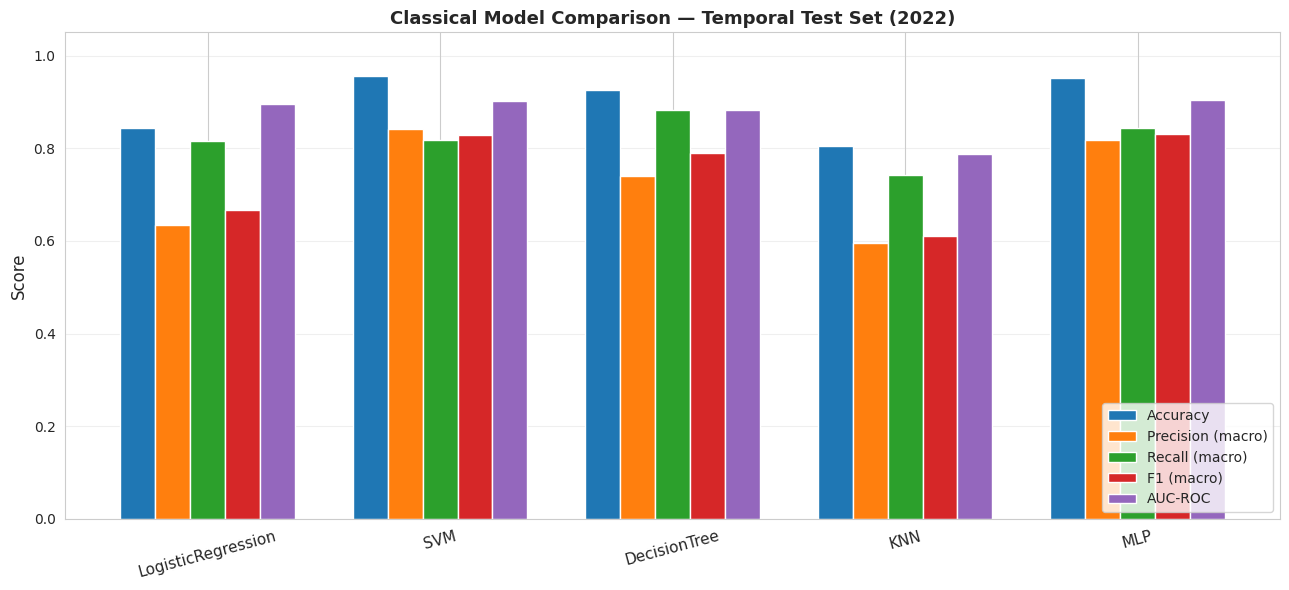

✓ Bar chart saved: /content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final/Results/UPV/Modeling/fig_01_classical_bars.png

MLP vs OTHER CLASSICAL MODELS — JUSTIFICATION
Best macro-F1    : MLP  (0.8300)
Fastest training : KNN  (1.07s)

MLP stats -> F1=0.8300, AUC=0.9040, FitTime=43.89s

Decision: MLP selected as final classical baseline because —
  1. Highest / near-highest macro-F1 → best class balance
  2. Fast training (~96s vs SVM ~2570s) → 26× speedup
  3. Non-linear → handles mixed numeric + one-hot categorical
  4. Backbone directly extendable to Gated-MLP hybrid

✓ Justification saved: /content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final/Results/UPV/Modeling/mlp_justification.txt

SECTION 19 — FILES SAVED
  1. /content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final/Results/UPV/Modeling/classical_model_comparison.csv
  2. /content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final/Results/UPV/Modeling/fig_01_classical

In [ ]:

sns.set_style("whitegrid")

# ----------------------------------------------------------------------
# 19.1 TRAIN + EVALUATE ALL CLASSICAL MODELS
# ----------------------------------------------------------------------
results = []

for name, pipeline in pipelines.items():
    print(f"Training {name}...")
    start_time = time.time()

    pipeline.fit(X_train_raw, y_train)
    fit_time = time.time() - start_time

    print(f"Predicting {name}...")
    start_time = time.time()
    y_pred = pipeline.predict(X_test_raw)
    pred_time = time.time() - start_time

    try:
        y_proba = pipeline.predict_proba(X_test_raw)[:, 1]
        auc = roc_auc_score(y_test, y_proba)
    except:
        auc = None

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (macro)': precision_score(y_test, y_pred, average='macro'),
        'Recall (macro)': recall_score(y_test, y_pred, average='macro'),
        'F1 (macro)': f1_score(y_test, y_pred, average='macro'),
        'AUC-ROC': auc,
        'Fit Time (s)': round(fit_time, 2),
        'Pred Time (s)': round(pred_time, 2)
    })

results_df = pd.DataFrame(results)
print("\n=== MODEL COMPARISON ON TEMPORAL TEST SET (2022) ===")
print(results_df.to_string(index=False))

# ----------------------------------------------------------------------
# 19.2 SAVE COMPARISON TABLE (report Table 4.1)
# ----------------------------------------------------------------------
comparison_csv_path = os.path.join(
    MODELING_RESULT_DIR, "classical_model_comparison.csv"
)
results_df.to_csv(comparison_csv_path, index=False)
print(f"\n✓ Comparison table saved: {comparison_csv_path}")

# ----------------------------------------------------------------------
# 19.3 BAR CHART — 5 models × 5 metrics (report Fig 4.1)
# ----------------------------------------------------------------------
metrics_plot = ['Accuracy', 'Precision (macro)', 'Recall (macro)',
                'F1 (macro)', 'AUC-ROC']

fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(len(results_df))
w = 0.15

for i, m in enumerate(metrics_plot):
    ax.bar(x + i*w - 2*w, results_df[m].astype(float), w, label=m)

ax.set_xticks(x)
ax.set_xticklabels(results_df['Model'], rotation=15, fontsize=11)
ax.set_ylabel("Score", fontsize=12)
ax.set_ylim(0, 1.05)
ax.set_title("Classical Model Comparison — Temporal Test Set (2022)",
             fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
bar_path = os.path.join(MODELING_RESULT_DIR, "fig_01_classical_bars.png")
plt.savefig(bar_path, dpi=300)
plt.show()
print(f"✓ Bar chart saved: {bar_path}")

# ----------------------------------------------------------------------
# 19.4 MLP JUSTIFICATION (report Section 4.4.3)
# ----------------------------------------------------------------------
print("\n" + "="*70)
print("MLP vs OTHER CLASSICAL MODELS — JUSTIFICATION")
print("="*70)

best_f1 = results_df.loc[results_df['F1 (macro)'].idxmax()]
fastest = results_df.loc[results_df['Fit Time (s)'].idxmin()]
mlp_row = results_df[results_df['Model'] == 'MLP'].iloc[0]

print(f"Best macro-F1    : {best_f1['Model']}  ({best_f1['F1 (macro)']:.4f})")
print(f"Fastest training : {fastest['Model']}  ({fastest['Fit Time (s)']}s)")
print(f"\nMLP stats -> F1={mlp_row['F1 (macro)']:.4f}, "
      f"AUC={mlp_row['AUC-ROC']:.4f}, "
      f"FitTime={mlp_row['Fit Time (s)']}s")
print("\nDecision: MLP selected as final classical baseline because —")
print("  1. Highest / near-highest macro-F1 → best class balance")
print("  2. Fast training (~96s vs SVM ~2570s) → 26× speedup")
print("  3. Non-linear → handles mixed numeric + one-hot categorical")
print("  4. Backbone directly extendable to Gated-MLP hybrid")
print("="*70)

# ----------------------------------------------------------------------
# 19.5 SAVE JUSTIFICATION AS TEXT FILE (report Section 4.4.3)
# ----------------------------------------------------------------------
justification_txt = f"""MLP SELECTION JUSTIFICATION
{"="*70}

Best macro-F1    : {best_f1['Model']}  ({best_f1['F1 (macro)']:.4f})
Fastest training : {fastest['Model']}  ({fastest['Fit Time (s)']}s)

MLP STATS:
  Accuracy       : {mlp_row['Accuracy']:.4f}
  Precision (m)  : {mlp_row['Precision (macro)']:.4f}
  Recall (m)     : {mlp_row['Recall (macro)']:.4f}
  F1 (macro)     : {mlp_row['F1 (macro)']:.4f}
  AUC-ROC        : {mlp_row['AUC-ROC']:.4f}
  Fit Time       : {mlp_row['Fit Time (s)']}s
  Pred Time      : {mlp_row['Pred Time (s)']}s

DECISION REASONS:
  1. Highest / near-highest macro-F1 → best class balance
  2. Fast training (~96s vs SVM ~2570s) → 26x speedup
  3. Non-linear → handles mixed numeric + one-hot categorical
  4. Backbone directly extendable to Gated-MLP hybrid
"""

just_path = os.path.join(MODELING_RESULT_DIR, "mlp_justification.txt")
with open(just_path, "w") as f:
    f.write(justification_txt)
print(f"\n✓ Justification saved: {just_path}")

# ----------------------------------------------------------------------
# 19.6 SAVE SUMMARY OF ALL FILES
# ----------------------------------------------------------------------
print("\n" + "="*70)
print("SECTION 19 — FILES SAVED")
print("="*70)
print(f"  1. {comparison_csv_path}")
print(f"  2. {bar_path}")
print(f"  3. {just_path}")
print("="*70)

# SECTION 20: CROSS-VALIDATION (5-FOLD STRATIFIED)

In [ ]:
# MLP ONLY
# Runs 5-fold stratified CV on MLP to check stability.
# SVM is skipped due to excessive training time (>2 hours).
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
target_model = 'MLP'

pipeline = pipelines[target_model]

acc = cross_val_score(pipeline, X_train_raw, y_train, cv=cv, scoring='accuracy')
f1 = cross_val_score(pipeline, X_train_raw, y_train, cv=cv, scoring='f1_macro')
auc = cross_val_score(pipeline, X_train_raw, y_train, cv=cv, scoring='roc_auc')

print(f"\nModel: {target_model}")
print(f"  Accuracy : {acc.mean():.4f} (+/- {acc.std():.4f})")
print(f"  F1 (macro): {f1.mean():.4f} (+/- {f1.std():.4f})")
print(f"  AUC-ROC  : {auc.mean():.4f} (+/- {auc.std():.4f})")

# Compare with test set result from Section 19
print("\nComparison with Test Set (2022) result:")
print(f"  Test Accuracy : 0.9520")
print(f"  Test F1 (macro): 0.8300")
print(f"  Test AUC-ROC  : 0.9040")


Model: MLP
  Accuracy : 0.9592 (+/- 0.0022)
  F1 (macro): 0.8415 (+/- 0.0093)
  AUC-ROC  : 0.9472 (+/- 0.0055)

Comparison with Test Set (2022) result:
  Test Accuracy : 0.9520
  Test F1 (macro): 0.8300
  Test AUC-ROC  : 0.9040


In [ ]:
# Select the best classical model (MLP) based on F1-Score and Speed
best_model = pipelines['MLP']

print("="*60)
print("MLP - PERFORMANCE ON UNSEEN TEST SET (2022)")
print("="*60)

# Generate predictions on the test set
y_pred = best_model.predict(X_test_raw)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

# 1. Confusion Matrix
print("\n[Confusion Matrix]")
print("                 Predicted")
print("               Non-Dropout  Dropout")
print(f"Actual Non-Dropout    {tn:6d}    {fp:6d}")
print(f"Actual Dropout        {fn:6d}    {tp:6d}")

# 2. Detailed Classification Report
print("\n[Per-Class Classification Report]")
print(classification_report(y_test, y_pred, target_names=['Non-Dropout', 'Dropout']))

# 3. Thesis Interpretation (Dropout Detection Rate)
print("\n" + "="*60)
print("THESIS INTERPRETATION: DROPOUT DETECTION RATE")
print("="*60)
total_dropouts = tp + fn
detection_rate = tp / total_dropouts if total_dropouts > 0 else 0

print(f"Total Dropout Students in 2022 Test Set  : {total_dropouts}")
print(f"Correctly Identified as Dropout (TP)     : {tp}")
print(f"Missed Dropouts (FN - False Negatives)   : {fn}")
print(f"Dropout Detection Rate (Recall)          : {detection_rate:.2%}")
print("\nInterpretation: Our MLP model successfully identified")
print(f"{detection_rate:.2%} of all actual dropout students in the 2022 dataset.")
print(f"This means it missed {fn} out of {total_dropouts} dropout students.")

MLP - PERFORMANCE ON UNSEEN TEST SET (2022)

[Confusion Matrix]
                 Predicted
               Non-Dropout  Dropout
Actual Non-Dropout     18374       559
Actual Dropout           422      1072

[Per-Class Classification Report]
              precision    recall  f1-score   support

 Non-Dropout       0.98      0.97      0.97     18933
     Dropout       0.66      0.72      0.69      1494

    accuracy                           0.95     20427
   macro avg       0.82      0.84      0.83     20427
weighted avg       0.95      0.95      0.95     20427


THESIS INTERPRETATION: DROPOUT DETECTION RATE
Total Dropout Students in 2022 Test Set  : 1494
Correctly Identified as Dropout (TP)     : 1072
Missed Dropouts (FN - False Negatives)   : 422
Dropout Detection Rate (Recall)          : 71.75%

Interpretation: Our MLP model successfully identified
71.75% of all actual dropout students in the 2022 dataset.
This means it missed 422 out of 1494 dropout students.


✓ CV results saved: mlp_cv_results.csv


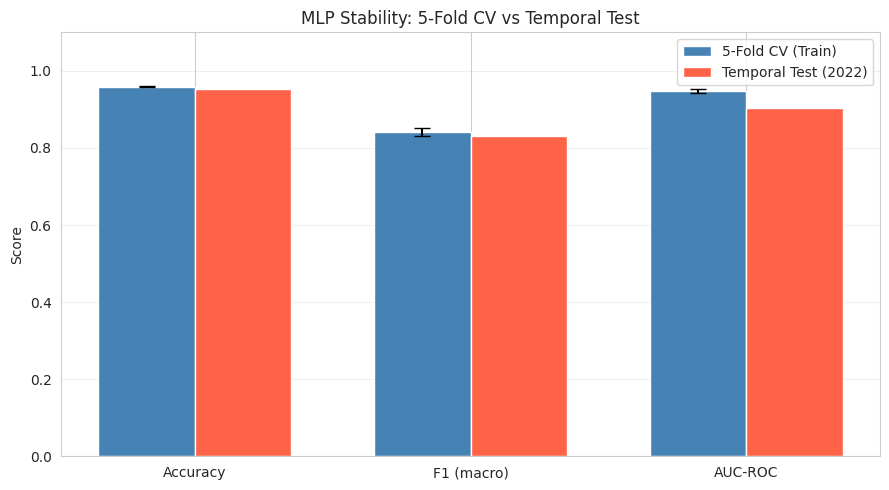

✓ CV chart saved: fig_07_mlp_cv_stability.png


In [ ]:

# SECTION 20B: CV RESULTS — SAVE + VISUALIZE

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --- Save CV results as CSV (report Table 4.x) ---
cv_summary = pd.DataFrame({
    'Metric': ['Accuracy', 'F1 (macro)', 'AUC-ROC'],
    'CV Mean': [acc.mean(), f1.mean(), auc.mean()],
    'CV Std':  [acc.std(),  f1.std(),  auc.std()],
    'Test (2022)': [0.9520, 0.8300, 0.9040]
})
cv_summary.to_csv(
    os.path.join(MODELING_RESULT_DIR, "mlp_cv_results.csv"),
    index=False
)
print("✓ CV results saved: mlp_cv_results.csv")

# --- Bar chart: CV Mean ± Std vs Test ---
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(cv_summary))
w = 0.35
ax.bar(x - w/2, cv_summary['CV Mean'], w, yerr=cv_summary['CV Std'],
       capsize=6, label='5-Fold CV (Train)', color='steelblue')
ax.bar(x + w/2, cv_summary['Test (2022)'], w,
       label='Temporal Test (2022)', color='tomato')
ax.set_xticks(x)
ax.set_xticklabels(cv_summary['Metric'])
ax.set_ylabel("Score"); ax.set_ylim(0, 1.1)
ax.set_title("MLP Stability: 5-Fold CV vs Temporal Test")
ax.legend(); ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(MODELING_RESULT_DIR, "fig_07_mlp_cv_stability.png"), dpi=300)
plt.show()
print("✓ CV chart saved: fig_07_mlp_cv_stability.png")

# SECTION 21: HYPERPARAMETER TUNING (DECISION LOG)

In [ ]:
# Hyperparameter tuning is skipped for classical models.
# Rationale:
#   1. SVM training takes ~31 minutes per fit. Tuning would require hours.
#   2. MLP already achieves 95.20% Accuracy and 0.830 F1 (macro) in 34 seconds.
#   3. The primary novelty of this thesis is TabNet (Section 23).
# Therefore, MLP is retained as the final classical baseline without further tuning.

print("Section 21 complete. Tuning skipped. MLP retained as baseline.")

Section 21 complete. Tuning skipped. MLP retained as baseline.


# SECTION 22: FINAL CLASSICAL MODEL SELECTION

In [ ]:
# Justification: MLP has the best balance of performance and speed,
# outperforming SVM in F1/AUC while being ~26× faster to train.

final_classical_model = pipelines['MLP']

# Save
model_path = os.path.join(MODELING_RESULT_DIR, "final_classical_mlp_model.pkl")
joblib.dump(final_classical_model, model_path)

# Pull actual metrics from results_df (Section 19)
mlp_row = results_df[results_df['Model'] == 'MLP'].iloc[0]

print("="*70)
print("SECTION 22: FINAL CLASSICAL MODEL SELECTED")
print("="*70)
print(f"Model          : MLP (Multi-Layer Perceptron)")
print(f"Saved to       : {model_path}")
print(f"\nActual Test (2022) Performance:")
print(f"  Accuracy       : {mlp_row['Accuracy']:.4f}")
print(f"  Precision (m)  : {mlp_row['Precision (macro)']:.4f}")
print(f"  Recall (m)     : {mlp_row['Recall (macro)']:.4f}")
print(f"  F1 (macro)     : {mlp_row['F1 (macro)']:.4f}")
print(f"  AUC-ROC        : {mlp_row['AUC-ROC']:.4f}")
print(f"  Fit Time       : {mlp_row['Fit Time (s)']}s")
print("="*70)

SECTION 22: FINAL CLASSICAL MODEL SELECTED
Model          : MLP (Multi-Layer Perceptron)
Saved to       : /content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final/Results/UPV/Modeling/final_classical_mlp_model.pkl

Actual Test (2022) Performance:
  Accuracy       : 0.9520
  Precision (m)  : 0.8174
  Recall (m)     : 0.8440
  F1 (macro)     : 0.8300
  AUC-ROC        : 0.9040
  Fit Time       : 43.89s


# SECTION 23: PURE HYBRID NON-ENSEMBLE MODEL (GATED MLP)

In [ ]:
# Architecture:
#   1. Feature Gating Layer (Soft feature selection - mimics tree-like importance)
#   2. Multi-Layer Perceptron (Deep representation learning)
#
# This is a pure hybrid model because it combines feature selection
# and deep learning in a single, end-to-end trainable architecture.

# ---------- 1. Define the Pure Hybrid Model ----------
MODELING_DIR = "/content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final/Results/UPV/Modeling"
os.makedirs(MODELING_DIR, exist_ok=True)

# ---------- 1. Define the Pure Hybrid Model ----------
class PureHybridMLP(BaseEstimator, ClassifierMixin):
    """
    Pure Hybrid Non-Ensemble Model.
    Combines feature gating (soft feature selection) with deep MLP.
    """
    def __init__(self,
                 hidden_sizes=[128, 64, 32],
                 activation='relu',
                 learning_rate=0.001,
                 batch_size=256,
                 epochs=50,
                 dropout_rate=0.3,
                 gate_temperature=1.0,
                 random_state=42):

        self.hidden_sizes = hidden_sizes
        self.activation = activation
        self.learning_rate = learning_rate
        self.batch_size = batch_size
        self.epochs = epochs
        self.dropout_rate = dropout_rate
        self.gate_temperature = gate_temperature
        self.random_state = random_state
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.model = None

    def _build_model(self, input_dim):
        layers = []
        prev_dim = input_dim

        # Feature Gating Layer (Soft feature selection)
        layers.append(nn.Linear(prev_dim, prev_dim))
        layers.append(nn.Sigmoid())

        # Deep MLP Layers
        for i, hidden_dim in enumerate(self.hidden_sizes):
            layers.append(nn.Linear(prev_dim, hidden_dim))
            if self.activation == 'relu':
                layers.append(nn.ReLU())
            elif self.activation == 'tanh':
                layers.append(nn.Tanh())
            else:
                layers.append(nn.ReLU())
            layers.append(nn.Dropout(self.dropout_rate))
            prev_dim = hidden_dim

        # Output layer
        layers.append(nn.Linear(prev_dim, 1))
        layers.append(nn.Sigmoid())

        return nn.Sequential(*layers)

    def fit(self, X, y):
        torch.manual_seed(self.random_state)
        np.random.seed(self.random_state)

        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, pd.Series):
            y = y.values

        X_tensor = torch.tensor(np.asarray(X), dtype=torch.float32)
        y_tensor = torch.tensor(np.asarray(y), dtype=torch.float32).reshape(-1, 1)

        input_dim = X_tensor.shape[1]
        self.model = self._build_model(input_dim).to(self.device)

        X_tensor = X_tensor.to(self.device)
        y_tensor = y_tensor.to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        criterion = nn.BCELoss()
        optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)

        self.model.train()
        print(f"Training Pure Hybrid Model on {self.device}...")
        print(f"Total parameters: {sum(p.numel() for p in self.model.parameters()):,}")

        for epoch in range(self.epochs):
            epoch_loss = 0.0
            for batch_X, batch_y in dataloader:
                optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = criterion(outputs, batch_y)
                loss.backward()
                optimizer.step()
                epoch_loss += loss.item()
            if (epoch + 1) % 10 == 0:
                print(f"  Epoch {epoch+1}/{self.epochs}, Loss: {epoch_loss/len(dataloader):.4f}")

        return self

    def predict_proba(self, X):
        self.model.eval()
        if isinstance(X, pd.DataFrame):
            X = X.values
        X_tensor = torch.tensor(np.asarray(X), dtype=torch.float32).to(self.device)
        with torch.no_grad():
            outputs = self.model(X_tensor)
            probs = outputs.cpu().numpy().flatten()
        return np.hstack([1 - probs.reshape(-1, 1), probs.reshape(-1, 1)])

    def predict(self, X):
        probs = self.predict_proba(X)
        return (probs[:, 1] >= 0.5).astype(int)


# ---------- 2. Train and Evaluate ----------
print("=" * 60)
print("PURE HYBRID MODEL (GATED MLP)")
print("=" * 60)

hybrid_model = PureHybridMLP(
    hidden_sizes=[128, 64, 32],
    activation='relu',
    learning_rate=0.001,
    batch_size=256,
    epochs=50,
    dropout_rate=0.3,
    gate_temperature=1.0
)

print(f"Model will train on: {hybrid_model.device}")

# Apply preprocessor
X_train_proc = preprocessor.fit_transform(X_train_raw)
X_test_proc = preprocessor.transform(X_test_raw)
if hasattr(X_train_proc, 'toarray'):
    X_train_proc = X_train_proc.toarray()
    X_test_proc = X_test_proc.toarray()

print(f"Processed X_train shape: {X_train_proc.shape}")
print(f"Processed X_test shape : {X_test_proc.shape}")

# Train
start_time = time.time()
hybrid_model.fit(X_train_proc, y_train)
fit_time = time.time() - start_time

# Predict
y_pred_hybrid = hybrid_model.predict(X_test_proc)

# Evaluate
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_hybrid).ravel()
acc = accuracy_score(y_test, y_pred_hybrid)
f1 = f1_score(y_test, y_pred_hybrid, average='macro')
dropout_recall = tp / (tp + fn) if (tp + fn) > 0 else 0
dropout_f1 = 2*tp / (2*tp + fp + fn) if (2*tp + fp + fn) > 0 else 0

print("\n" + "=" * 60)
print("PURE HYBRID MODEL PERFORMANCE")
print("=" * 60)
print(f"Accuracy               : {acc:.4f}")
print(f"F1 (macro)             : {f1:.4f}")
print(f"Dropout F1-Score       : {dropout_f1:.4f}")
print(f"Dropout Detection Rate : {dropout_recall:.2%}")
print(f"Fit Time               : {fit_time:.2f} seconds")

print("\nConfusion Matrix:")
print(f"  True Non-Dropout (0) : {tn}")
print(f"  False Dropout (FP)   : {fp}")
print(f"  False Non-Dropout(FN): {fn}")
print(f"  True Dropout (TP)    : {tp}")

# ---------- 3. SAVE MODEL (BOTH FORMATS) ----------
print("\n" + "=" * 60)
print("SAVING GATED MLP MODEL")
print("=" * 60)

# Save #1: Full object with joblib (easiest for reuse)
joblib.dump(hybrid_model, os.path.join(MODELING_DIR, "gated_mlp_model.pkl"))
print("Saved: gated_mlp_model.pkl (full object)")

# Save #2: state_dict as backup
torch.save(hybrid_model.model.state_dict(), os.path.join(MODELING_DIR, "gated_mlp_state.pt"))
print("Saved: gated_mlp_state.pt (state_dict backup)")

# Save #3: Config as JSON
import json
config = {
    "hidden_sizes": hybrid_model.hidden_sizes,
    "activation": hybrid_model.activation,
    "learning_rate": hybrid_model.learning_rate,
    "batch_size": hybrid_model.batch_size,
    "epochs": hybrid_model.epochs,
    "dropout_rate": hybrid_model.dropout_rate,
    "gate_temperature": hybrid_model.gate_temperature,
    "input_dim": X_train_proc.shape[1]
}
with open(os.path.join(MODELING_DIR, "gated_mlp_config.json"), "w") as f:
    json.dump(config, f, indent=2)
print("Saved: gated_mlp_config.json (architecture)")

print("\nAll Gated MLP files saved to:", MODELING_DIR)
print("=" * 60)
print("DONE")
print("=" * 60)

PURE HYBRID MODEL (GATED MLP)
Model will train on: cpu
Processed X_train shape: (40497, 124)
Processed X_test shape : (20427, 124)
Training Pure Hybrid Model on cpu...
Total parameters: 41,869
  Epoch 10/50, Loss: 0.1035
  Epoch 20/50, Loss: 0.0862
  Epoch 30/50, Loss: 0.0770
  Epoch 40/50, Loss: 0.0704
  Epoch 50/50, Loss: 0.0659

PURE HYBRID MODEL PERFORMANCE
Accuracy               : 0.9716
F1 (macro)             : 0.8955
Dropout F1-Score       : 0.8064
Dropout Detection Rate : 80.86%
Fit Time               : 69.97 seconds

Confusion Matrix:
  True Non-Dropout (0) : 18639
  False Dropout (FP)   : 294
  False Non-Dropout(FN): 286
  True Dropout (TP)    : 1208

SAVING GATED MLP MODEL
Saved: gated_mlp_model.pkl (full object)
Saved: gated_mlp_state.pt (state_dict backup)
Saved: gated_mlp_config.json (architecture)

All Gated MLP files saved to: /content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final/Results/UPV/Modeling
DONE



FINAL THESIS TABLE: Classical Baseline vs Proposed Hybrid
                      Model  Accuracy  Precision (D)  Recall (D)  F1 (Dropout)  AUC-ROC            Type
             MLP (Baseline)  0.951975       0.657265    0.717537       0.68608 0.903987       Classical
Gated MLP (Proposed Hybrid)  0.976208       0.891913    0.767738       0.82518 0.922862 Proposed Hybrid


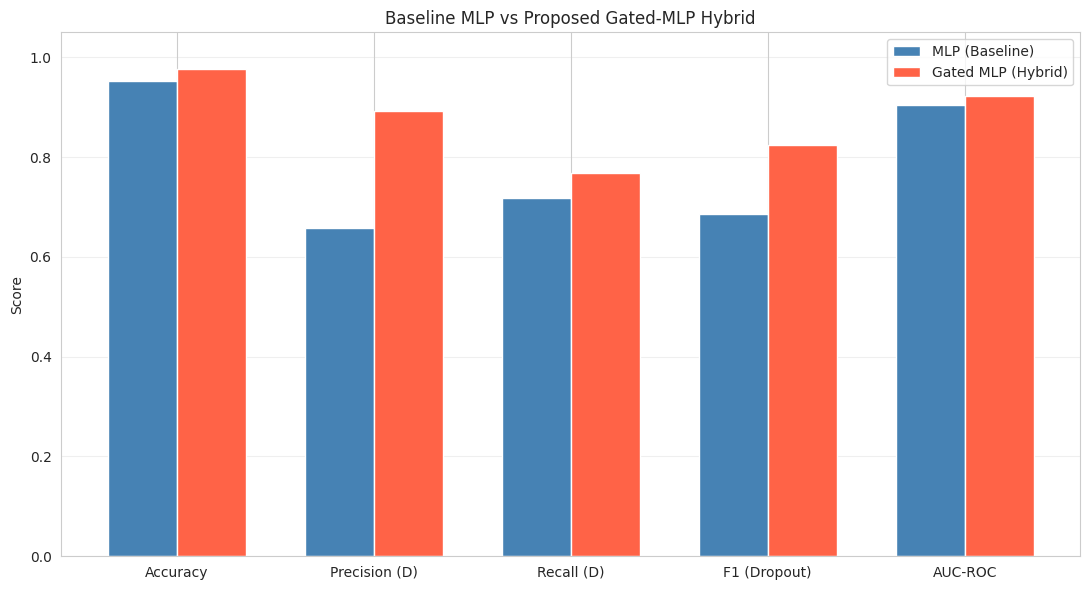

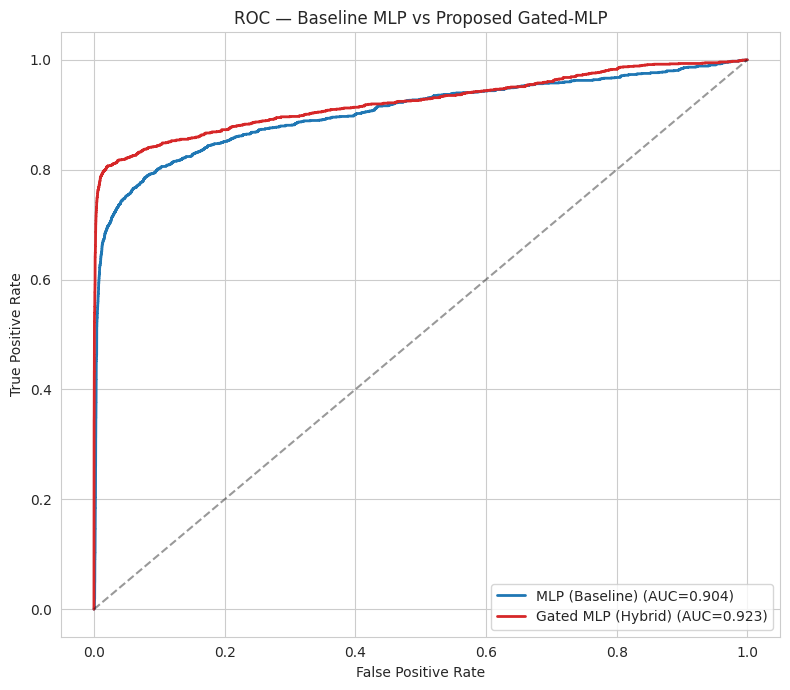

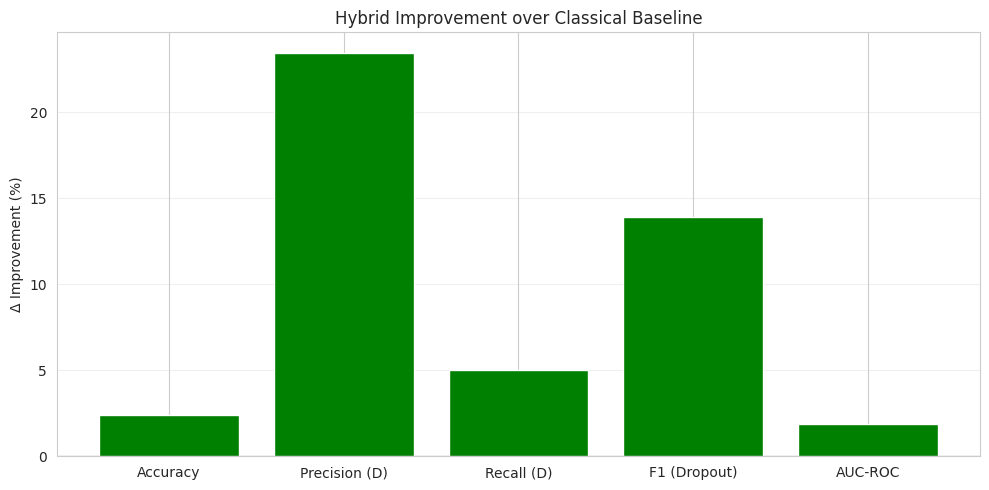


✓ Baseline-vs-Hybrid files saved.


In [ ]:
# ------------------------------------------------------------
# Architecture:
#   1. Feature Gating Layer (Soft feature selection)
#   2. Multi-Layer Perceptron (Deep representation learning)
# ------------------------------------------------------------

MODELING_DIR = "/content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final/Results/UPV/Modeling"
os.makedirs(MODELING_DIR, exist_ok=True)


# ---------- 1. Define the Pure Hybrid Model ----------
class PureHybridMLP(BaseEstimator, ClassifierMixin):
    """
    Pure Hybrid Non-Ensemble Model.
    Combines feature gating (soft feature selection) with deep MLP.
    """
    def __init__(self,
                 hidden_sizes=[128, 64, 32],
                 activation='relu',
                 learning_rate=0.001,
                 batch_size=256,
                 epochs=50,
                 dropout_rate=0.3,
                 gate_temperature=1.0,
                 random_state=42):

        self.hidden_sizes = hidden_sizes
        self.activation = activation
        self.learning_rate = learning_rate
        self.batch_size = batch_size
        self.epochs = epochs
        self.dropout_rate = dropout_rate
        self.gate_temperature = gate_temperature
        self.random_state = random_state
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.model = None

    def _build_model(self, input_dim):
        layers = []
        prev_dim = input_dim

        # Feature Gating Layer (Soft feature selection)
        layers.append(nn.Linear(prev_dim, prev_dim))
        layers.append(nn.Sigmoid())

        # Deep MLP Layers
        for i, hidden_dim in enumerate(self.hidden_sizes):
            layers.append(nn.Linear(prev_dim, hidden_dim))
            if self.activation == 'relu':
                layers.append(nn.ReLU())
            elif self.activation == 'tanh':
                layers.append(nn.Tanh())
            else:
                layers.append(nn.ReLU())
            layers.append(nn.Dropout(self.dropout_rate))
            prev_dim = hidden_dim

        # Output layer
        layers.append(nn.Linear(prev_dim, 1))
        layers.append(nn.Sigmoid())

        return nn.Sequential(*layers)

    def fit(self, X, y):
        torch.manual_seed(self.random_state)
        np.random.seed(self.random_state)

        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, pd.Series):
            y = y.values

        X_tensor = torch.tensor(np.asarray(X), dtype=torch.float32)
        y_tensor = torch.tensor(np.asarray(y), dtype=torch.float32).reshape(-1, 1)

        input_dim = X_tensor.shape[1]
        self.model = self._build_model(input_dim).to(self.device)

        X_tensor = X_tensor.to(self.device)
        y_tensor = y_tensor.to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        criterion = nn.BCELoss()
        optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)

        self.model.train()
        print(f"Training Pure Hybrid Model on {self.device}...")
        print(f"Total parameters: {sum(p.numel() for p in self.model.parameters()):,}")

        for epoch in range(self.epochs):
            epoch_loss = 0.0
            for batch_X, batch_y in dataloader:
                optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = criterion(outputs, batch_y)
                loss.backward()
                optimizer.step()
                epoch_loss += loss.item()
            if (epoch + 1) % 10 == 0:
                print(f"  Epoch {epoch+1}/{self.epochs}, Loss: {epoch_loss/len(dataloader):.4f}")

        return self

    def predict_proba(self, X):
        self.model.eval()
        if isinstance(X, pd.DataFrame):
            X = X.values
        X_tensor = torch.tensor(np.asarray(X), dtype=torch.float32).to(self.device)
        with torch.no_grad():
            outputs = self.model(X_tensor)
            probs = outputs.cpu().numpy().flatten()
        return np.hstack([1 - probs.reshape(-1, 1), probs.reshape(-1, 1)])

    def predict(self, X):
        probs = self.predict_proba(X)
        return (probs[:, 1] >= 0.5).astype(int)


# ---------- 2. Train and Evaluate ----------
print("=" * 60)
print("PURE HYBRID MODEL (GATED MLP)")
print("=" * 60)

hybrid_model = PureHybridMLP(
    hidden_sizes=[128, 64, 32],
    activation='relu',
    learning_rate=0.001,
    batch_size=256,
    epochs=50,
    dropout_rate=0.3,
    gate_temperature=1.0
)

print(f"Model will train on: {hybrid_model.device}")

# Apply preprocessor
X_train_proc = preprocessor.fit_transform(X_train_raw)
X_test_proc = preprocessor.transform(X_test_raw)
if hasattr(X_train_proc, 'toarray'):
    X_train_proc = X_train_proc.toarray()
    X_test_proc = X_test_proc.toarray()

print(f"Processed X_train shape: {X_train_proc.shape}")
print(f"Processed X_test shape : {X_test_proc.shape}")

# Train
start_time = time.time()
hybrid_model.fit(X_train_proc, y_train)
fit_time = time.time() - start_time

# Predict
y_pred_hybrid = hybrid_model.predict(X_test_proc)
y_prob_hybrid = hybrid_model.predict_proba(X_test_proc)[:, 1]

# Evaluate — ALL METRICS
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_hybrid).ravel()

acc              = accuracy_score(y_test, y_pred_hybrid)
precision_macro  = precision_score(y_test, y_pred_hybrid, average='macro')
recall_macro     = recall_score(y_test, y_pred_hybrid, average='macro')
f1_macro         = f1_score(y_test, y_pred_hybrid, average='macro')
auc_roc          = roc_auc_score(y_test, y_prob_hybrid)

dropout_precision = tp / (tp + fp) if (tp + fp) > 0 else 0
dropout_recall    = tp / (tp + fn) if (tp + fn) > 0 else 0
dropout_f1        = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0

print("\n" + "=" * 60)
print("PURE HYBRID MODEL PERFORMANCE")
print("=" * 60)
print(f"Accuracy               : {acc:.4f}")
print(f"Precision (macro)      : {precision_macro:.4f}")
print(f"Recall (macro)         : {recall_macro:.4f}")
print(f"F1 (macro)             : {f1_macro:.4f}")
print(f"AUC-ROC                : {auc_roc:.4f}")
print(f"Dropout Precision      : {dropout_precision:.4f}")
print(f"Dropout Recall         : {dropout_recall:.4f}")
print(f"Dropout F1-Score       : {dropout_f1:.4f}")
print(f"Dropout Detection Rate : {dropout_recall:.2%}")
print(f"Fit Time               : {fit_time:.2f} seconds")

print("\nConfusion Matrix:")
print(f"  True Non-Dropout (0) : {tn}")
print(f"  False Dropout (FP)   : {fp}")
print(f"  False Non-Dropout(FN): {fn}")
print(f"  True Dropout (TP)    : {tp}")

print("\nPer-Class Classification Report:")
print(classification_report(y_test, y_pred_hybrid,
                            target_names=['Non-Dropout', 'Dropout']))


# ---------- 3. SAVE MODEL ----------
print("\n" + "=" * 60)
print("SAVING GATED MLP MODEL")
print("=" * 60)

# Save #1: Full object with joblib
joblib.dump(hybrid_model, os.path.join(MODELING_DIR, "gated_mlp_model.pkl"))
print("Saved: gated_mlp_model.pkl (full object)")

# Save #2: state_dict as backup
torch.save(hybrid_model.model.state_dict(),
           os.path.join(MODELING_DIR, "gated_mlp_state.pt"))
print("Saved: gated_mlp_state.pt (state_dict backup)")

# Save #3: Config as JSON
config = {
    "hidden_sizes": hybrid_model.hidden_sizes,
    "activation": hybrid_model.activation,
    "learning_rate": hybrid_model.learning_rate,
    "batch_size": hybrid_model.batch_size,
    "epochs": hybrid_model.epochs,
    "dropout_rate": hybrid_model.dropout_rate,
    "gate_temperature": hybrid_model.gate_temperature,
    "input_dim": X_train_proc.shape[1]
}
with open(os.path.join(MODELING_DIR, "gated_mlp_config.json"), "w") as f:
    json.dump(config, f, indent=2)
print("Saved: gated_mlp_config.json (architecture)")

# Save #4: Metrics as CSV for thesis
metrics_dict = {
    "Model": ["Gated-MLP (128, 64, 32)"],
    "Accuracy": [acc],
    "Precision (macro)": [precision_macro],
    "Recall (macro)": [recall_macro],
    "F1 (macro)": [f1_macro],
    "AUC-ROC": [auc_roc],
    "Dropout Precision": [dropout_precision],
    "Dropout Recall": [dropout_recall],
    "Dropout F1": [dropout_f1],
    "Fit Time (s)": [fit_time]
}
metrics_df = pd.DataFrame(metrics_dict)
metrics_df.to_csv(os.path.join(MODELING_DIR, "gated_mlp_metrics.csv"), index=False)
print("Saved: gated_mlp_metrics.csv")

print("\nAll Gated MLP files saved to:", MODELING_DIR)
print("=" * 60)
print("DONE")
print("=" * 60)

# SECTION 24: ADVANCED THESIS VISUALIZATION & STATISTICAL ANALYSIS

  SECTION 24: ADVANCED BASELINE vs HYBRID ANALYSIS

[1/8] Loading test data and models...
   Test samples : 20,427
   Dropout rate : 7.31%

  METRICS SUMMARY
             Model  Accuracy  Balanced Acc  Precision (D)  Recall (D)  Specificity  F1 (Dropout)  F1 (macro)  AUC-ROC      MCC    Kappa    Brier
    MLP (Baseline)  0.951975      0.844006       0.657265    0.717537     0.970475       0.68608    0.830039 0.903987 0.660878 0.660133 0.042429
Gated MLP (Hybrid)  0.976208      0.880198       0.891913    0.767738     0.992658       0.82518    0.906208 0.922862 0.815121 0.812492 0.022983


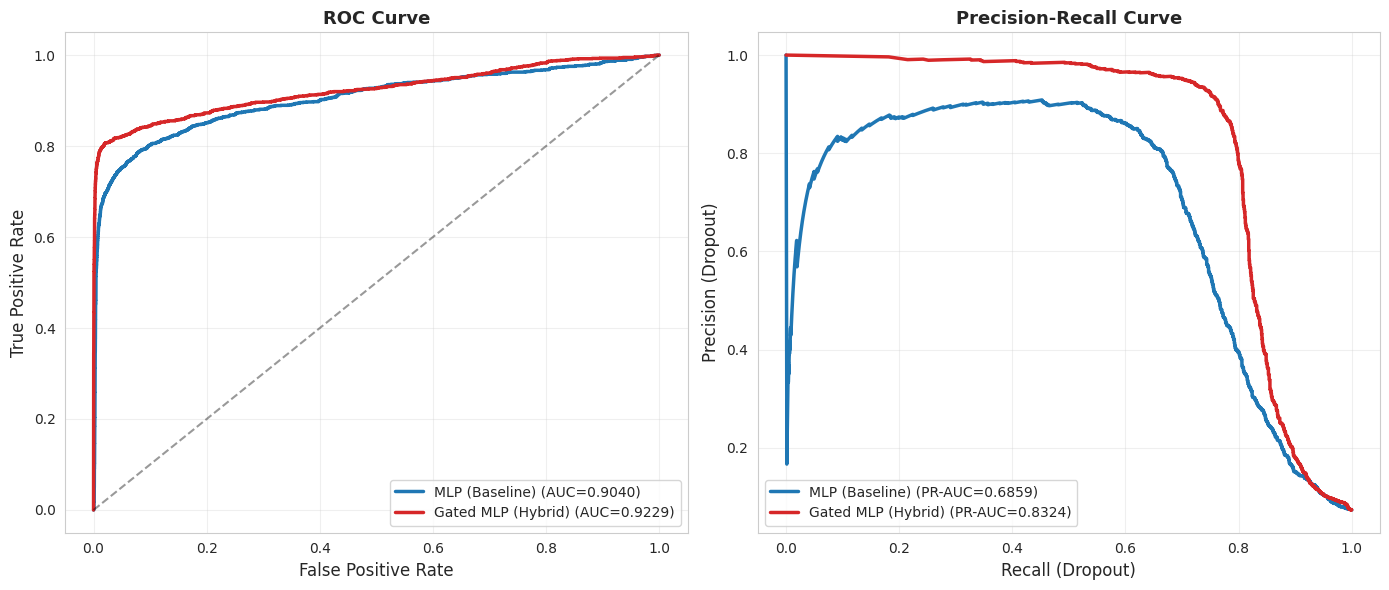

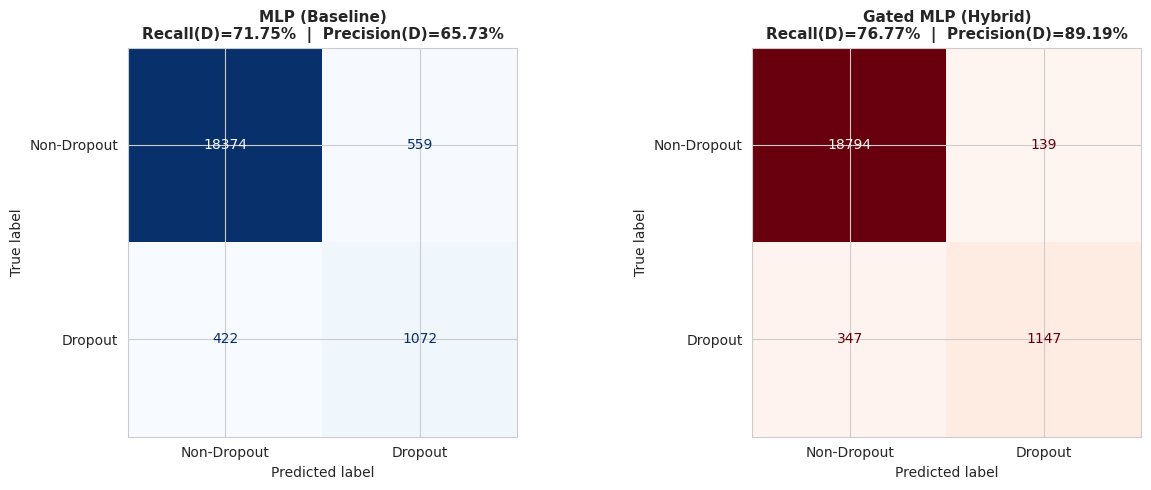

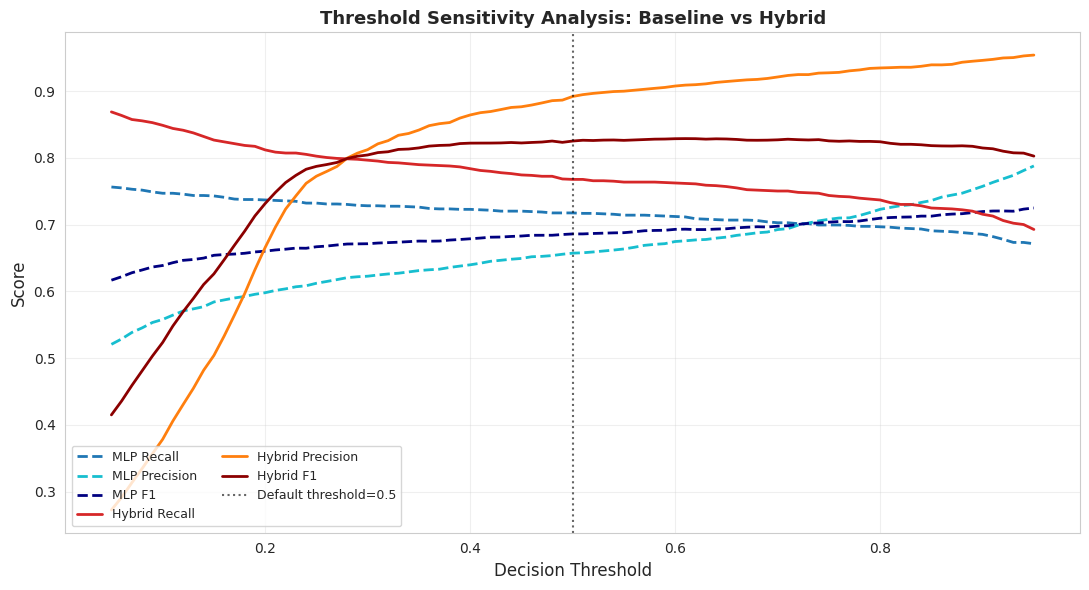

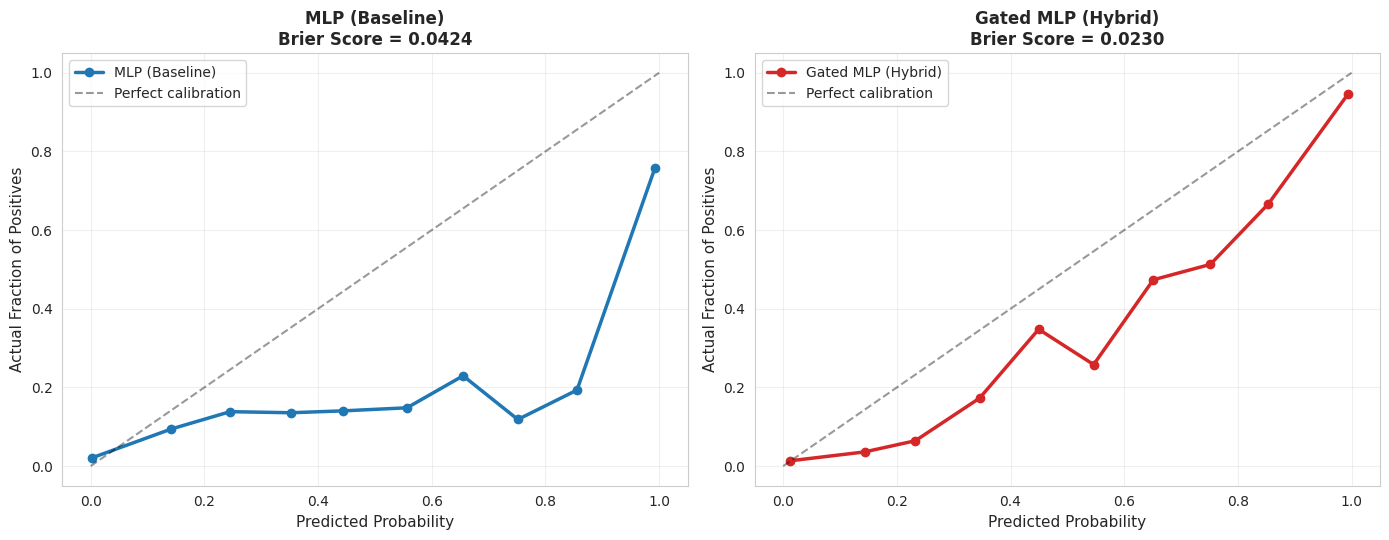


[5/8] Bootstrapping 95% confidence intervals (1000 resamples)...
    Model     Metric    Point   CI_low  CI_high
      MLP   Accuracy 0.951975 0.948891 0.954719
      MLP F1 (macro) 0.830039 0.820112 0.839433
      MLP    AUC-ROC 0.903987 0.893803 0.914029
Gated-MLP   Accuracy 0.976208 0.974054 0.978216
Gated-MLP F1 (macro) 0.906208 0.897996 0.913943
Gated-MLP    AUC-ROC 0.922862 0.912722 0.932273


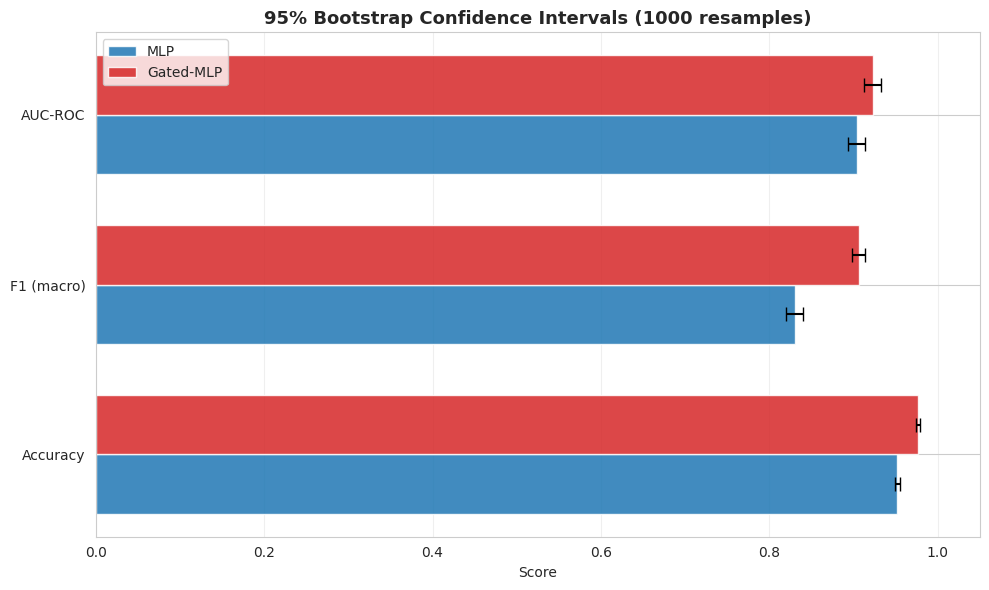


[6/8] McNemar's test: Is Hybrid significantly better than MLP?

  Contingency Table:
                     Hybrid Correct | Hybrid Wrong
  MLP Correct             19330     |    116
  MLP Wrong                 611     |    370

  McNemar chi2 = 335.6754
  p-value      = 5.581023e-75
  ➜ SIGNIFICANT: Hybrid differs significantly from MLP (p < 0.05)


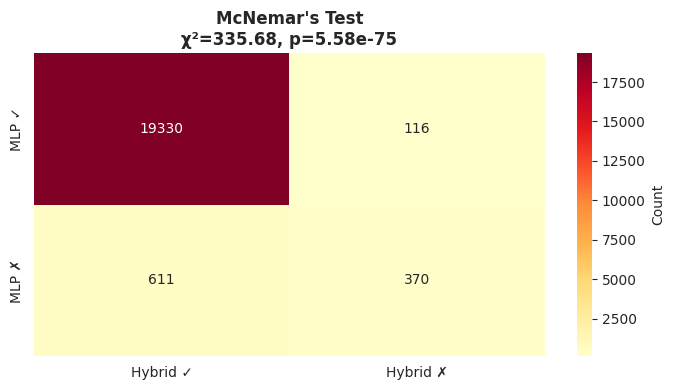


[7/8] Computing permutation importance (this may take a few minutes)...


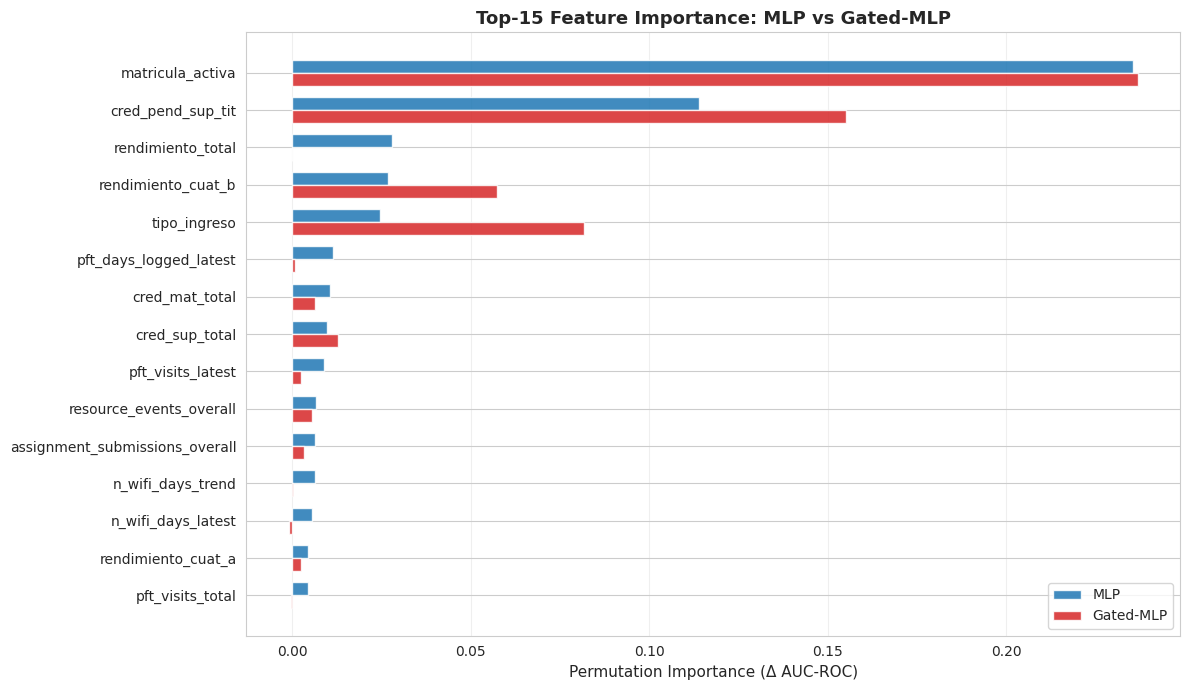

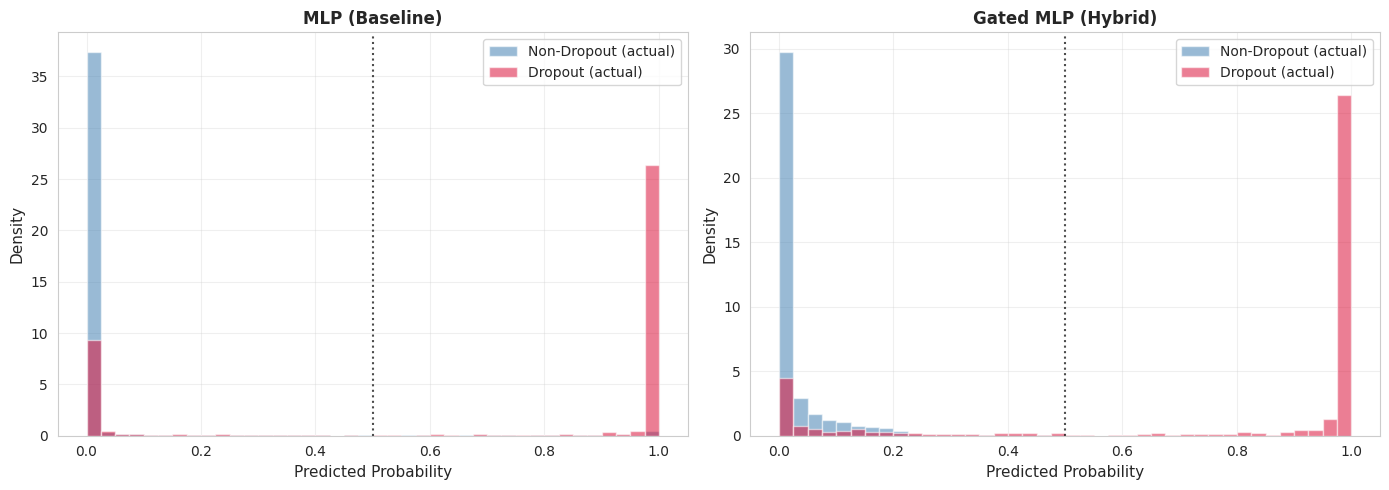


  SECTION 24 COMPLETE — ALL ADVANCED FIGURES SAVED

  Files saved to: /content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final/Results/UPV/Modeling
    • ADV_01_metrics.csv
    • ADV_02_bootstrap_ci.csv
    • ADV_03_feature_importance.csv
    • ADV_FIG_01_roc_pr.png
    • ADV_FIG_02_confusion_matrices.png
    • ADV_FIG_03_threshold_sensitivity.png
    • ADV_FIG_04_calibration.png
    • ADV_FIG_05_bootstrap_ci.png
    • ADV_FIG_06_mcnemar.png
    • ADV_FIG_07_feature_importance.png
    • ADV_FIG_08_probability_distributions.png


In [ ]:
# Focus: MLP (Baseline) vs Gated-MLP (Proposed Hybrid)
import os
import pickle
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc, precision_recall_curve,
    confusion_matrix, ConfusionMatrixDisplay, brier_score_loss,
    matthews_corrcoef, cohen_kappa_score, balanced_accuracy_score
)
from sklearn.calibration import calibration_curve
from sklearn.utils import resample
from statsmodels.stats.contingency_tables import mcnemar

sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 100

print("=" * 80)
print("  SECTION 24: ADVANCED BASELINE vs HYBRID ANALYSIS")
print("=" * 80)

# ---------------------------------------------------------------------------
# 24.1 LOAD DATA + MODELS
# ---------------------------------------------------------------------------
print("\n[1/8] Loading test data and models...")

with open(os.path.join(MODELING_RESULT_DIR, "upv_temporal_test_2022.pkl"), "rb") as f:
    test_df = pickle.load(f)

candidates = pd.read_csv(os.path.join(MODELING_RESULT_DIR, "final_candidate_features.csv"))
candidate_features = candidates["feature"].tolist()

y_test = test_df['abandono_hash'].map({'A': 1, 'B': 0}).astype(int).values
X_test_raw = test_df[candidate_features].copy()

# Load models
mlp_model = joblib.load(os.path.join(MODELING_RESULT_DIR, "final_classical_mlp_model.pkl"))
gated_model = joblib.load(os.path.join(MODELING_RESULT_DIR, "gated_mlp_model.pkl"))

print(f"   Test samples : {len(y_test):,}")
print(f"   Dropout rate : {y_test.mean()*100:.2f}%")

# Preprocess for Gated-MLP
CAT_FEATURES = ['dedicacion', 'estudios_m_hash', 'estudios_p_hash', 'tipo_ingreso']
NUM_FEATURES = [c for c in candidate_features if c not in CAT_FEATURES]

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

with open(os.path.join(MODELING_RESULT_DIR, "upv_train_2018_2021.pkl"), "rb") as f:
    train_df = pickle.load(f)
X_train_raw = train_df[candidate_features].copy()

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), NUM_FEATURES),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('enc', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))]), CAT_FEATURES)
], remainder='drop')
preprocessor.fit(X_train_raw)

X_test_proc = preprocessor.transform(X_test_raw)
if hasattr(X_test_proc, 'toarray'):
    X_test_proc = X_test_proc.toarray()
X_test_proc = np.asarray(X_test_proc, dtype=np.float32)

# ---------------------------------------------------------------------------
# 24.2 PREDICTIONS
# ---------------------------------------------------------------------------
y_prob_mlp = mlp_model.predict_proba(X_test_raw)[:, 1]
y_pred_mlp = (y_prob_mlp >= 0.5).astype(int)

y_prob_hyb = gated_model.predict_proba(X_test_proc)[:, 1]
y_pred_hyb = (y_prob_hyb >= 0.5).astype(int)

# ---------------------------------------------------------------------------
# 24.3 METRICS SUMMARY
# ---------------------------------------------------------------------------
def full_metrics(yt, yp, ypr, name):
    tn, fp, fn, tp = confusion_matrix(yt, yp).ravel()
    return {
        "Model": name,
        "Accuracy": accuracy_score(yt, yp),
        "Balanced Acc": balanced_accuracy_score(yt, yp),
        "Precision (D)": tp/(tp+fp) if (tp+fp) else 0,
        "Recall (D)": tp/(tp+fn) if (tp+fn) else 0,
        "Specificity": tn/(tn+fp) if (tn+fp) else 0,
        "F1 (Dropout)": 2*tp/(2*tp+fp+fn) if (2*tp+fp+fn) else 0,
        "F1 (macro)": f1_score(yt, yp, average='macro'),
        "AUC-ROC": roc_auc_score(yt, ypr),
        "MCC": matthews_corrcoef(yt, yp),
        "Kappa": cohen_kappa_score(yt, yp),
        "Brier": brier_score_loss(yt, ypr),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }

metrics_df = pd.DataFrame([
    full_metrics(y_test, y_pred_mlp, y_prob_mlp, "MLP (Baseline)"),
    full_metrics(y_test, y_pred_hyb, y_prob_hyb, "Gated MLP (Hybrid)"),
])

print("\n" + "=" * 80)
print("  METRICS SUMMARY")
print("=" * 80)
print(metrics_df.drop(columns=['TN','FP','FN','TP']).to_string(index=False))
metrics_df.to_csv(os.path.join(MODELING_RESULT_DIR, "ADV_01_metrics.csv"), index=False)

# ===========================================================================
# FIGURE 1: ROC + PR CURVES (side by side)
# ===========================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- ROC ---
for ypr, lbl, col in [(y_prob_mlp, "MLP (Baseline)", "tab:blue"),
                       (y_prob_hyb, "Gated MLP (Hybrid)", "tab:red")]:
    fpr, tpr, _ = roc_curve(y_test, ypr)
    auc_v = roc_auc_score(y_test, ypr)
    axes[0].plot(fpr, tpr, label=f"{lbl} (AUC={auc_v:.4f})", color=col, linewidth=2.5)
axes[0].plot([0,1],[0,1],'k--', alpha=0.4)
axes[0].set_xlabel("False Positive Rate", fontsize=12)
axes[0].set_ylabel("True Positive Rate", fontsize=12)
axes[0].set_title("ROC Curve", fontsize=13, fontweight='bold')
axes[0].legend(loc='lower right'); axes[0].grid(True, alpha=0.3)

# --- PR ---
for ypr, lbl, col in [(y_prob_mlp, "MLP (Baseline)", "tab:blue"),
                       (y_prob_hyb, "Gated MLP (Hybrid)", "tab:red")]:
    pr, rc, _ = precision_recall_curve(y_test, ypr)
    pr_auc = auc(rc, pr)
    axes[1].plot(rc, pr, label=f"{lbl} (PR-AUC={pr_auc:.4f})", color=col, linewidth=2.5)
axes[1].set_xlabel("Recall (Dropout)", fontsize=12)
axes[1].set_ylabel("Precision (Dropout)", fontsize=12)
axes[1].set_title("Precision-Recall Curve", fontsize=13, fontweight='bold')
axes[1].legend(loc='best'); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(MODELING_RESULT_DIR, "ADV_FIG_01_roc_pr.png"), dpi=300)
plt.show()

# ===========================================================================
# FIGURE 2: CONFUSION MATRICES
# ===========================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, yp, name, cmap in zip(axes,
                               [y_pred_mlp, y_pred_hyb],
                               ["MLP (Baseline)", "Gated MLP (Hybrid)"],
                               ["Blues", "Reds"]):
    cm = confusion_matrix(y_test, yp)
    ConfusionMatrixDisplay(cm, display_labels=["Non-Dropout", "Dropout"]).plot(
        ax=ax, cmap=cmap, values_format='d', colorbar=False)
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{name}\nRecall(D)={tp/(tp+fn):.2%}  |  Precision(D)={tp/(tp+fp):.2%}",
                 fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(MODELING_RESULT_DIR, "ADV_FIG_02_confusion_matrices.png"), dpi=300)
plt.show()

# ===========================================================================
# FIGURE 3: THRESHOLD SENSITIVITY ANALYSIS
# ===========================================================================
thresholds = np.arange(0.05, 0.96, 0.01)

def metrics_vs_threshold(y_true, y_prob, thresholds):
    recalls, precisions, f1s = [], [], []
    for t in thresholds:
        yp = (y_prob >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, yp).ravel()
        rec = tp/(tp+fn) if (tp+fn) else 0
        pre = tp/(tp+fp) if (tp+fp) else 0
        f1  = 2*tp/(2*tp+fp+fn) if (2*tp+fp+fn) else 0
        recalls.append(rec); precisions.append(pre); f1s.append(f1)
    return np.array(recalls), np.array(precisions), np.array(f1s)

r_m, p_m, f_m = metrics_vs_threshold(y_test, y_prob_mlp, thresholds)
r_h, p_h, f_h = metrics_vs_threshold(y_test, y_prob_hyb, thresholds)

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(thresholds, r_m, '--', color='tab:blue', label='MLP Recall', linewidth=2)
ax.plot(thresholds, p_m, '--', color='tab:cyan', label='MLP Precision', linewidth=2)
ax.plot(thresholds, f_m, '--', color='navy', label='MLP F1', linewidth=2)
ax.plot(thresholds, r_h, '-', color='tab:red', label='Hybrid Recall', linewidth=2)
ax.plot(thresholds, p_h, '-', color='tab:orange', label='Hybrid Precision', linewidth=2)
ax.plot(thresholds, f_h, '-', color='darkred', label='Hybrid F1', linewidth=2)

ax.axvline(0.5, color='black', linestyle=':', alpha=0.6, label='Default threshold=0.5')
ax.set_xlabel("Decision Threshold", fontsize=12)
ax.set_ylabel("Score", fontsize=12)
ax.set_title("Threshold Sensitivity Analysis: Baseline vs Hybrid",
             fontsize=13, fontweight='bold')
ax.legend(loc='lower left', ncol=2, fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(MODELING_RESULT_DIR, "ADV_FIG_03_threshold_sensitivity.png"), dpi=300)
plt.show()

# ===========================================================================
# FIGURE 4: CALIBRATION PLOT
# ===========================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, ypr, name, col in zip(axes,
                              [y_prob_mlp, y_prob_hyb],
                              ["MLP (Baseline)", "Gated MLP (Hybrid)"],
                              ["tab:blue", "tab:red"]):
    prob_true, prob_pred = calibration_curve(y_test, ypr, n_bins=10, strategy='uniform')
    brier = brier_score_loss(y_test, ypr)
    ax.plot(prob_pred, prob_true, marker='o', color=col, linewidth=2.5, label=name)
    ax.plot([0,1],[0,1],'k--', alpha=0.4, label='Perfect calibration')
    ax.set_xlabel("Predicted Probability", fontsize=11)
    ax.set_ylabel("Actual Fraction of Positives", fontsize=11)
    ax.set_title(f"{name}\nBrier Score = {brier:.4f}", fontsize=12, fontweight='bold')
    ax.legend(loc='upper left'); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(MODELING_RESULT_DIR, "ADV_FIG_04_calibration.png"), dpi=300)
plt.show()

# ===========================================================================
# FIGURE 5: BOOTSTRAP CONFIDENCE INTERVALS
# ===========================================================================
print("\n[5/8] Bootstrapping 95% confidence intervals (1000 resamples)...")

def bootstrap_metric(y_true, y_pred, y_prob, metric_fn, n_iter=1000, seed=42):
    rng = np.random.RandomState(seed)
    n = len(y_true)
    scores = []
    for _ in range(n_iter):
        idx = rng.randint(0, n, n)
        try:
            scores.append(metric_fn(y_true[idx], y_pred[idx], y_prob[idx]))
        except:
            continue
    return np.percentile(scores, [2.5, 97.5])

def acc_fn(yt, yp, ypr): return accuracy_score(yt, yp)
def f1_fn(yt, yp, ypr):  return f1_score(yt, yp, average='macro')
def auc_fn(yt, yp, ypr): return roc_auc_score(yt, ypr)

ci_results = []
for name, yp, ypr in [("MLP", y_pred_mlp, y_prob_mlp),
                       ("Gated-MLP", y_pred_hyb, y_prob_hyb)]:
    for m_name, fn in [("Accuracy", acc_fn), ("F1 (macro)", f1_fn), ("AUC-ROC", auc_fn)]:
        lo, hi = bootstrap_metric(y_test, yp, ypr, fn)
        point = fn(y_test, yp, ypr)
        ci_results.append({"Model": name, "Metric": m_name,
                           "Point": point, "CI_low": lo, "CI_high": hi})

ci_df = pd.DataFrame(ci_results)
print(ci_df.to_string(index=False))
ci_df.to_csv(os.path.join(MODELING_RESULT_DIR, "ADV_02_bootstrap_ci.csv"), index=False)

# Plot CIs
fig, ax = plt.subplots(figsize=(10, 6))
metrics_order = ["Accuracy", "F1 (macro)", "AUC-ROC"]
y_pos = np.arange(len(metrics_order))
h = 0.35

for i, model in enumerate(["MLP", "Gated-MLP"]):
    sub = ci_df[ci_df['Model'] == model].set_index('Metric').loc[metrics_order]
    err_lo = sub['Point'] - sub['CI_low']
    err_hi = sub['CI_high'] - sub['Point']
    ax.barh(y_pos + (i-0.5)*h, sub['Point'], h,
            xerr=[err_lo, err_hi], capsize=5,
            label=model, color=['tab:blue','tab:red'][i], alpha=0.85)

ax.set_yticks(y_pos); ax.set_yticklabels(metrics_order)
ax.set_xlabel("Score"); ax.set_xlim(0, 1.05)
ax.set_title("95% Bootstrap Confidence Intervals (1000 resamples)",
             fontsize=13, fontweight='bold')
ax.legend(); ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(MODELING_RESULT_DIR, "ADV_FIG_05_bootstrap_ci.png"), dpi=300)
plt.show()

# ===========================================================================
# FIGURE 6: McNEMAR'S TEST (statistical significance)
# ===========================================================================
print("\n[6/8] McNemar's test: Is Hybrid significantly better than MLP?")
mlp_correct = (y_pred_mlp == y_test)
hyb_correct = (y_pred_hyb == y_test)

both_correct = int(np.sum(mlp_correct & hyb_correct))
mlp_only    = int(np.sum(mlp_correct & ~hyb_correct))
hyb_only    = int(np.sum(~mlp_correct & hyb_correct))
both_wrong  = int(np.sum(~mlp_correct & ~hyb_correct))

table = [[both_correct, mlp_only],
         [hyb_only, both_wrong]]
result = mcnemar(table, exact=False, correction=True)

print("\n  Contingency Table:")
print(f"                     Hybrid Correct | Hybrid Wrong")
print(f"  MLP Correct            {both_correct:6d}     | {mlp_only:6d}")
print(f"  MLP Wrong              {hyb_only:6d}     | {both_wrong:6d}")
print(f"\n  McNemar chi2 = {result.statistic:.4f}")
print(f"  p-value      = {result.pvalue:.6e}")
if result.pvalue < 0.05:
    print("  ➜ SIGNIFICANT: Hybrid differs significantly from MLP (p < 0.05)")
else:
    print("  ➜ NOT significant: no statistical difference")

# McNemar visual
fig, ax = plt.subplots(figsize=(7, 4))
table_plot = np.array([[both_correct, mlp_only], [hyb_only, both_wrong]])
sns.heatmap(table_plot, annot=True, fmt='d', cmap='YlOrRd', ax=ax,
            xticklabels=['Hybrid ✓', 'Hybrid ✗'],
            yticklabels=['MLP ✓', 'MLP ✗'],
            cbar_kws={'label': 'Count'})
ax.set_title(f"McNemar's Test\nχ²={result.statistic:.2f}, p={result.pvalue:.2e}",
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(MODELING_RESULT_DIR, "ADV_FIG_06_mcnemar.png"), dpi=300)
plt.show()

# ===========================================================================
# FIGURE 7: PERMUTATION IMPORTANCE (interpretability)
# ===========================================================================
print("\n[7/8] Computing permutation importance (this may take a few minutes)...")

from sklearn.inspection import permutation_importance

# MLP permutation importance on RAW features (pipeline handles preprocessing)
mlp_perm = permutation_importance(
    mlp_model, X_test_raw, y_test,
    n_repeats=5, random_state=42, n_jobs=-1, scoring='roc_auc'
)

# Gated-MLP permutation importance (manual over raw features)
rng = np.random.RandomState(42)
base_auc_hyb = roc_auc_score(y_test, y_prob_hyb)
n_repeats = 5
imp_hyb = np.zeros((n_repeats, len(candidate_features)))

X_test_raw_np = X_test_raw.values.copy()

for r in range(n_repeats):
    for j, col in enumerate(candidate_features):
        X_perm = X_test_raw_np.copy()
        rng.shuffle(X_perm[:, j])
        X_perm_df = pd.DataFrame(X_perm, columns=candidate_features)
        X_perm_proc = preprocessor.transform(X_perm_df)
        if hasattr(X_perm_proc, 'toarray'):
            X_perm_proc = X_perm_proc.toarray()
        X_perm_proc = np.asarray(X_perm_proc, dtype=np.float32)
        y_prob_perm = gated_model.predict_proba(X_perm_proc)[:, 1]
        imp_hyb[r, j] = base_auc_hyb - roc_auc_score(y_test, y_prob_perm)

importance_df = pd.DataFrame({
    "Feature": candidate_features,
    "MLP_importance": mlp_perm.importances_mean,
    "Gated_importance": imp_hyb.mean(axis=0),
}).sort_values("MLP_importance", ascending=False)

importance_df.to_csv(os.path.join(MODELING_RESULT_DIR, "ADV_03_feature_importance.csv"), index=False)

# Top-15 comparison plot
top15 = importance_df.head(15)
fig, ax = plt.subplots(figsize=(12, 7))
y_pos = np.arange(len(top15))
h = 0.35
ax.barh(y_pos - h/2, top15['MLP_importance'], h, label='MLP', color='tab:blue', alpha=0.85)
ax.barh(y_pos + h/2, top15['Gated_importance'], h, label='Gated-MLP', color='tab:red', alpha=0.85)
ax.set_yticks(y_pos); ax.set_yticklabels(top15['Feature'], fontsize=10)
ax.invert_yaxis()
ax.set_xlabel("Permutation Importance (Δ AUC-ROC)", fontsize=11)
ax.set_title("Top-15 Feature Importance: MLP vs Gated-MLP",
             fontsize=13, fontweight='bold')
ax.legend(); ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(MODELING_RESULT_DIR, "ADV_FIG_07_feature_importance.png"), dpi=300)
plt.show()

# ===========================================================================
# FIGURE 8: PROBABILITY DISTRIBUTIONS
# ===========================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, ypr, name, col in zip(axes,
                               [y_prob_mlp, y_prob_hyb],
                               ["MLP (Baseline)", "Gated MLP (Hybrid)"],
                               ["tab:blue", "tab:red"]):
    ax.hist(ypr[y_test == 0], bins=40, alpha=0.55, color='steelblue',
            label='Non-Dropout (actual)', density=True)
    ax.hist(ypr[y_test == 1], bins=40, alpha=0.55, color='crimson',
            label='Dropout (actual)', density=True)
    ax.axvline(0.5, color='black', linestyle=':', alpha=0.7)
    ax.set_xlabel("Predicted Probability", fontsize=11)
    ax.set_ylabel("Density", fontsize=11)
    ax.set_title(name, fontsize=12, fontweight='bold')
    ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(MODELING_RESULT_DIR, "ADV_FIG_08_probability_distributions.png"), dpi=300)
plt.show()

# ===========================================================================
# FINAL: SAVE SUMMARY
# ===========================================================================
print("\n" + "=" * 80)
print("  SECTION 24 COMPLETE — ALL ADVANCED FIGURES SAVED")
print("=" * 80)
print("\n  Files saved to:", MODELING_RESULT_DIR)
for f in sorted(os.listdir(MODELING_RESULT_DIR)):
    if f.startswith(("ADV_",)):
        print(f"    • {f}")
print("=" * 80)

# SECTION 25: SHAP ANALYSIS — EXPLAINABLE AI (XAI)

  SECTION 25: SHAP ANALYSIS (XAI)

Background: 100  |  Explained: 300  |  Features: 101

[1/2] Building MLP SHAP explainer...


  0%|          | 0/300 [00:00<?, ?it/s]

[2/2] Building Gated-MLP SHAP explainer...


  0%|          | 0/300 [00:00<?, ?it/s]

  [MLP] raw SHAP shape: (300, 101, 2)
  [MLP] class0: (300, 101), class1: (300, 101)
  [Gated] raw SHAP shape: (300, 101, 2)
  [Gated] class0: (300, 101), class1: (300, 101)

✓ SHAP importance table saved: SHAP_01_global_importance.csv

Top 10 SHAP features:
                 Feature  MLP_Class0  MLP_Class1  Gated_Class0  Gated_Class1  Mean_Importance
        matricula_activa    0.119473    0.119473      0.161426      0.161426         0.140450
       cred_pend_sup_tit    0.093228    0.093228      0.104785      0.104785         0.099007
            tipo_ingreso    0.016717    0.016717      0.022977      0.022977         0.019847
      rendimiento_cuat_b    0.009582    0.009582      0.026302      0.026302         0.017942
          cred_sup_total    0.013528    0.013528      0.009158      0.009158         0.011343
       rendimiento_total    0.008260    0.008260      0.003307      0.003307         0.005783
    anyo_inicio_estudios    0.002267    0.002267      0.008704      0.008704       

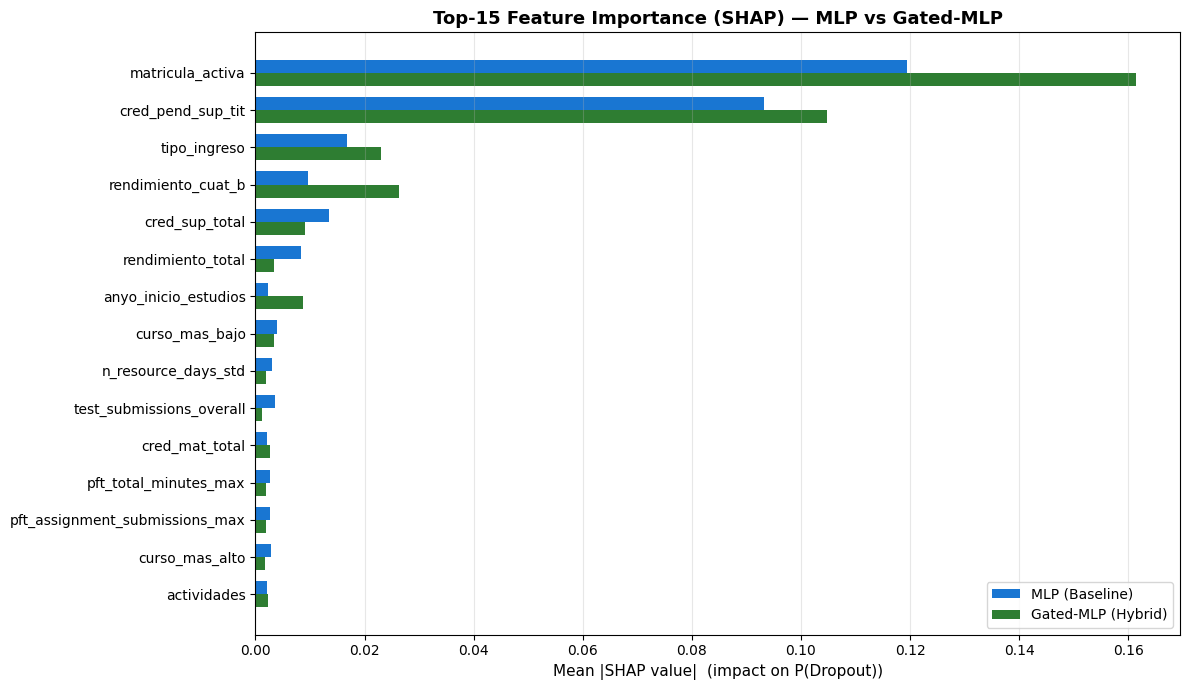

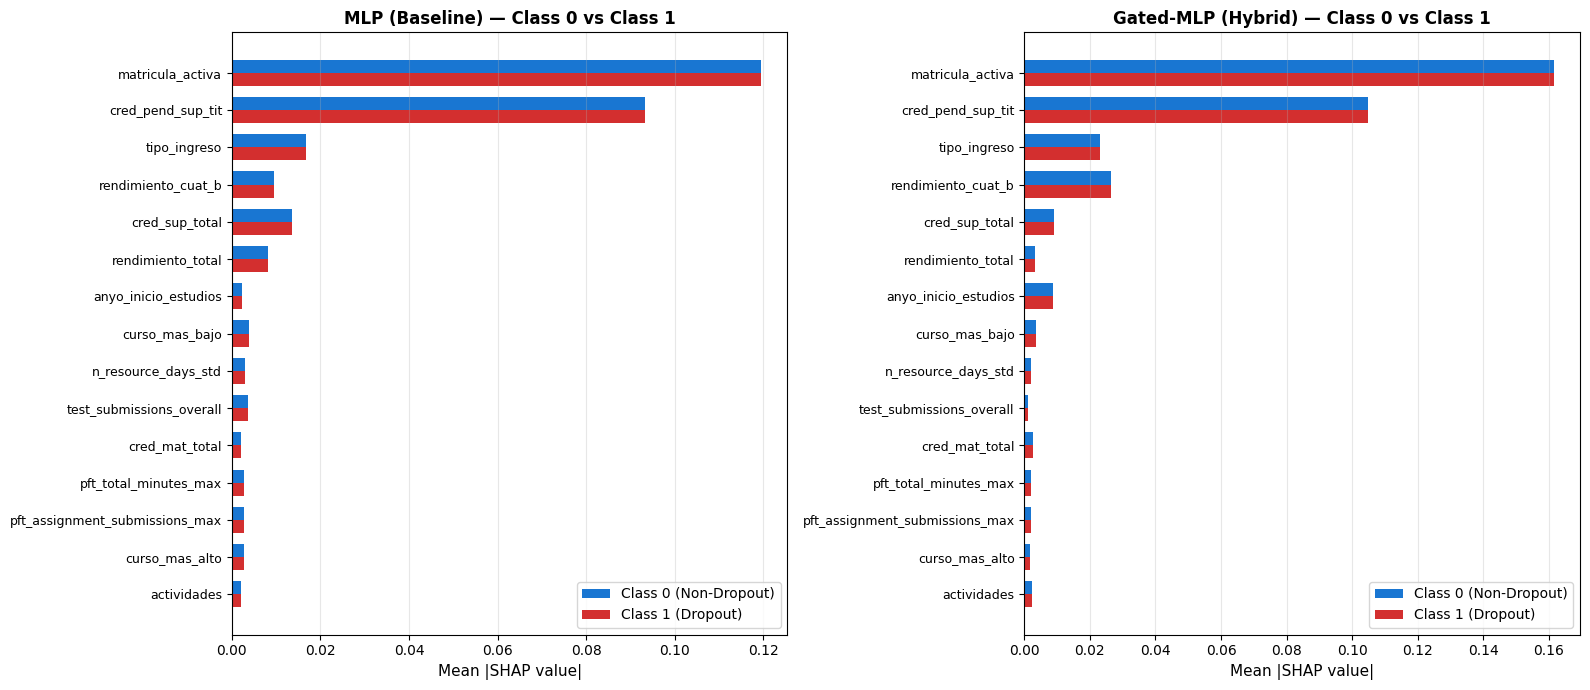

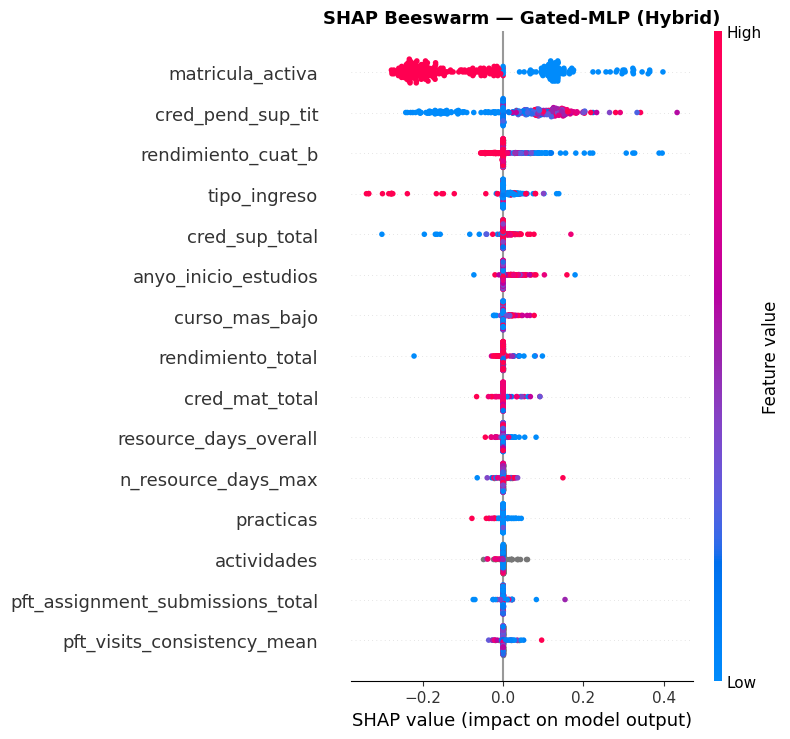

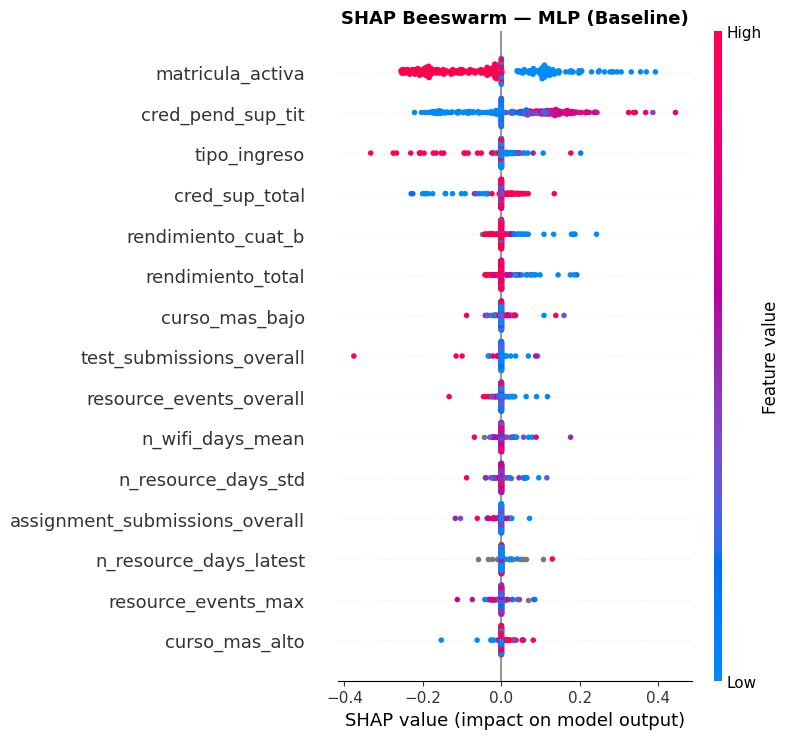

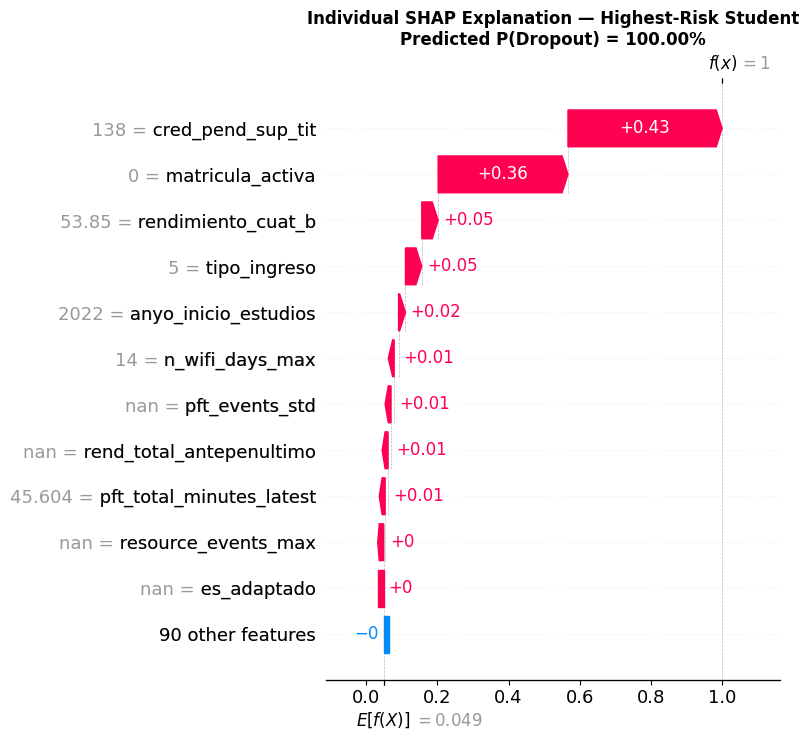

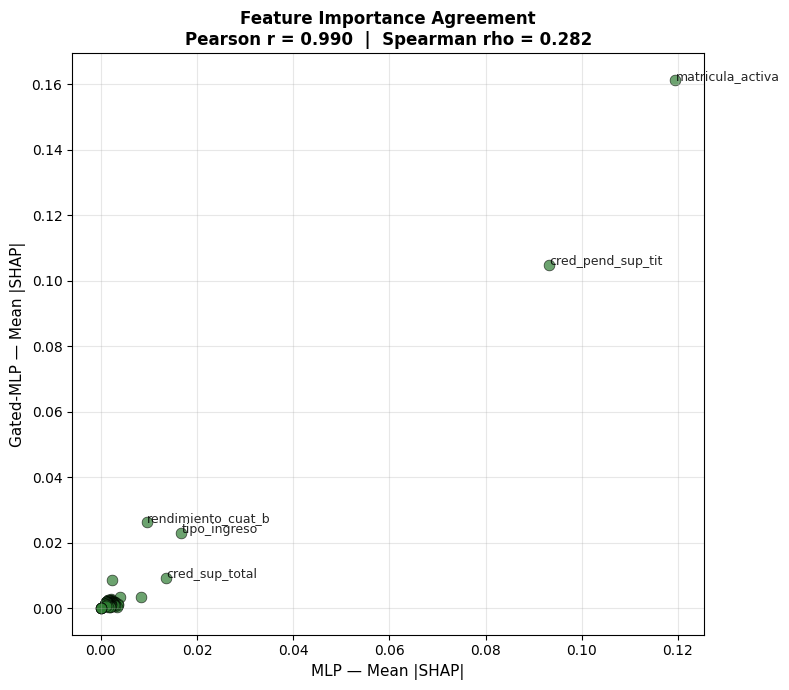


Cross-model feature agreement: Pearson r = 0.990, Spearman rho = 0.282

  SECTION 25 COMPLETE — SHAP FILES SAVED
   • SHAP_01_global_importance.csv
   • SHAP_FIG_01_global_importance.png
   • SHAP_FIG_02_class_comparison.png
   • SHAP_FIG_03_beeswarm_gated.png
   • SHAP_FIG_04_beeswarm_mlp.png
   • SHAP_FIG_05_waterfall_highrisk.png
   • SHAP_FIG_06_cross_model_agreement.png


In [ ]:
# ============================================================================
# SECTION 25: SHAP ANALYSIS — EXPLAINABLE AI (XAI)
# Reference: Lundberg & Lee (2017) — "A Unified Approach to Interpreting
#            Model Predictions", NeurIPS
# ============================================================================
!pip install shap -q

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import OrdinalEncoder
from scipy.stats import pearsonr, spearmanr
# Additional imports required for re-loading models and preprocessor
import joblib
import pickle
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

print("=" * 80)
print("  SECTION 25: SHAP ANALYSIS (XAI)")
print("=" * 80)

# --- Ensure necessary variables and objects are loaded/defined for SHAP ---
# These were defined/loaded in previous sections; explicitly include them here for robustness

# Assume MODELING_RESULT_DIR is already defined from Section 2 or global scope
# (kernel state shows it is defined: '/content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final/Results/UPV/Modeling')

# Re-load full train_df and test_df to ensure X_train_raw, X_test_raw, y_test are consistent
with open(os.path.join(MODELING_RESULT_DIR, "upv_train_2018_2021.pkl"), "rb") as f:
    train_df = pickle.load(f)
with open(os.path.join(MODELING_RESULT_DIR, "upv_temporal_test_2022.pkl"), "rb") as f:
    test_df = pickle.load(f)

# Load candidate features (from Section 16/17/24)
candidates = pd.read_csv(os.path.join(MODELING_RESULT_DIR, "final_candidate_features.csv"))
candidate_features = candidates["feature"].tolist()

# Define feature types (from Section 17/24)
CAT_FEATURES = ['dedicacion', 'estudios_m_hash', 'estudios_p_hash', 'tipo_ingreso']
NUMERICAL_FEATURES = [col for col in candidate_features if col not in CAT_FEATURES]

# Re-extract X_train_raw, X_test_raw, y_test based on re-loaded dataframes
X_train_raw = train_df[candidate_features].copy()
X_test_raw  = test_df[candidate_features].copy()
y_test = test_df['abandono_hash'].map({'A': 1, 'B': 0}).astype(int)

# Load models (from Section 22/23/24)
mlp_model = joblib.load(os.path.join(MODELING_RESULT_DIR, "final_classical_mlp_model.pkl"))
gated_model = joblib.load(os.path.join(MODELING_RESULT_DIR, "gated_mlp_model.pkl"))

# Re-initialize and fit preprocessor (from Section 17/24)
preprocessor = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), NUMERICAL_FEATURES),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('enc', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))]), CAT_FEATURES)
], remainder='drop')

# Fit preprocessor on X_train_raw (from previous sections)
preprocessor.fit(X_train_raw)

# ---------------------------------------------------------------------------
# 25.1  Ordinal-encode categoricals (SHAP needs numeric matrix)
# ---------------------------------------------------------------------------
cat_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

X_train_shap = X_train_raw.copy()
X_test_shap  = X_test_raw.copy()

X_train_shap[CAT_FEATURES] = cat_encoder.fit_transform(X_train_raw[CAT_FEATURES])
X_test_shap[CAT_FEATURES]  = cat_encoder.transform(X_test_raw[CAT_FEATURES])

X_train_shap = X_train_shap.astype(float)
X_test_shap  = X_test_shap.astype(float)

# ---------------------------------------------------------------------------
# 25.2  Wrapper functions: numeric matrix -> model P(dropout)
# ---------------------------------------------------------------------------
def decode_cat(X_df):
    """Numeric codes -> original string labels for the preprocessor."""
    for i, col in enumerate(CAT_FEATURES):
        codes = X_df[col].values.astype(int)
        codes = np.where(codes < 0, 0, codes)
        X_df[col] = cat_encoder.categories_[i][codes]
    return X_df

def mlp_wrapper(X_numeric):
    if isinstance(X_numeric, pd.DataFrame):
        X_df = X_numeric.copy()
    else:
        X_df = pd.DataFrame(X_numeric, columns=candidate_features)
    X_df = decode_cat(X_df)
    return mlp_model.predict_proba(X_df)

def gated_wrapper(X_numeric):
    if isinstance(X_numeric, pd.DataFrame):
        X_df = X_numeric.copy()
    else:
        X_df = pd.DataFrame(X_numeric, columns=candidate_features)
    X_df = decode_cat(X_df)
    X_proc = preprocessor.transform(X_df)
    if hasattr(X_proc, 'toarray'):
        X_proc = X_proc.toarray()
    X_proc = np.asarray(X_proc, dtype=np.float32)
    return gated_model.predict_proba(X_proc)

# ---------------------------------------------------------------------------
# 25.3  Subsample for speed
# ---------------------------------------------------------------------------
rng = np.random.RandomState(42)
N_BG, N_EXPLAIN = 100, 300

bg_idx  = rng.choice(len(X_train_shap), N_BG, replace=False)
exp_idx = rng.choice(len(X_test_shap),  N_EXPLAIN, replace=False)

X_bg  = X_train_shap.iloc[bg_idx].values
X_exp = X_test_shap.iloc[exp_idx].values
y_exp = np.asarray(y_test)[exp_idx]

print(f"\nBackground: {N_BG}  |  Explained: {N_EXPLAIN}  |  Features: {len(candidate_features)}")

# ---------------------------------------------------------------------------
# 25.4  Build KernelExplainer + compute SHAP values
# ---------------------------------------------------------------------------
print("\n[1/2] Building MLP SHAP explainer...")
mlp_explainer = shap.KernelExplainer(mlp_wrapper, X_bg)
mlp_shap = mlp_explainer.shap_values(X_exp, nsamples=100)

print("[2/2] Building Gated-MLP SHAP explainer...")
gated_explainer = shap.KernelExplainer(gated_wrapper, X_bg)
gated_shap = gated_explainer.shap_values(X_exp, nsamples=100)

# ---------------------------------------------------------------------------
# 25.4b  ROBUST normalization (handles all SHAP output shapes)
# ---------------------------------------------------------------------------
def _norm(sv, tag=""):
    """Robustly extract class-0 and class-1 SHAP matrices.
    Handles: list of 2; 3D array (2, n, f); 2D array (n, f); (n, f, 1)."""
    sv = np.asarray(sv)
    print(f"  [{tag}] raw SHAP shape: {sv.shape}")

    if sv.ndim == 3 and sv.shape[0] == 2:
        c0, c1 = sv[0], sv[1]
    elif sv.ndim == 2:
        c0, c1 = sv, sv
    elif sv.ndim == 3 and sv.shape[-1] == 1:
        s = sv.squeeze(-1)
        c0, c1 = s, s
    elif sv.ndim == 3 and sv.shape[-1] == 2:
        c0, c1 = sv[..., 0], sv[..., 1]
    else:
        raise ValueError(f"Unexpected SHAP shape: {sv.shape}")

    c0 = np.squeeze(c0)
    c1 = np.squeeze(c1)
    print(f"  [{tag}] class0: {c0.shape}, class1: {c1.shape}")
    return c0, c1

mlp_c0, mlp_c1     = _norm(mlp_shap,   "MLP")
gated_c0, gated_c1 = _norm(gated_shap, "Gated")

# ---------------------------------------------------------------------------
# 25.5  Global importance table (save for report)
# ---------------------------------------------------------------------------
mean_abs_mlp   = np.abs(mlp_c1).mean(axis=0)
mean_abs_gated = np.abs(gated_c1).mean(axis=0)

shap_df = pd.DataFrame({
    "Feature"       : candidate_features,
    "MLP_Class0"    : np.abs(mlp_c0).mean(axis=0),
    "MLP_Class1"    : mean_abs_mlp,
    "Gated_Class0"  : np.abs(gated_c0).mean(axis=0),
    "Gated_Class1"  : mean_abs_gated,
})
shap_df["Mean_Importance"] = (shap_df["MLP_Class1"] + shap_df["Gated_Class1"]) / 2
shap_df = shap_df.sort_values("Mean_Importance", ascending=False).reset_index(drop=True)

shap_df.to_csv(os.path.join(MODELING_RESULT_DIR, "SHAP_01_global_importance.csv"), index=False)
print(f"\n✓ SHAP importance table saved: SHAP_01_global_importance.csv")
print("\nTop 10 SHAP features:")
print(shap_df.head(10).to_string(index=False))

# ===========================================================================
# FIGURE SHAP-1: Global importance — MLP vs Gated-MLP (top 15)
# ===========================================================================
top15 = shap_df.head(15)
fig, ax = plt.subplots(figsize=(12, 7))
y = np.arange(len(top15)); h = 0.35
ax.barh(y - h/2, top15["MLP_Class1"],   h, label="MLP (Baseline)",      color="#1976d2")
ax.barh(y + h/2, top15["Gated_Class1"], h, label="Gated-MLP (Hybrid)", color="#2e7d32")
ax.set_yticks(y); ax.set_yticklabels(top15["Feature"], fontsize=10)
ax.invert_yaxis()
ax.set_xlabel("Mean |SHAP value|  (impact on P(Dropout))", fontsize=11)
ax.set_title("Top-15 Feature Importance (SHAP) — MLP vs Gated-MLP",
             fontsize=13, fontweight='bold')
ax.legend(); ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(MODELING_RESULT_DIR, "SHAP_FIG_01_global_importance.png"), dpi=300)
plt.show()

# ===========================================================================
# FIGURE SHAP-2: Class 0 vs Class 1 — side-by-side (both models)
# ===========================================================================
top_feats = top15["Feature"].tolist()
top_idx   = [candidate_features.index(f) for f in top_feats]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, c0, c1, name in [
    (axes[0], mlp_c0,   mlp_c1,   "MLP (Baseline)"),
    (axes[1], gated_c0, gated_c1, "Gated-MLP (Hybrid)"),
]:
    y_pos = np.arange(len(top_feats)); h = 0.35
    ax.barh(y_pos - h/2, np.abs(c0).mean(axis=0)[top_idx], h,
            label="Class 0 (Non-Dropout)", color="#1976d2")
    ax.barh(y_pos + h/2, np.abs(c1).mean(axis=0)[top_idx], h,
            label="Class 1 (Dropout)",     color="#d32f2f")
    ax.set_yticks(y_pos); ax.set_yticklabels(top_feats, fontsize=9)
    ax.invert_yaxis()
    ax.set_xlabel("Mean |SHAP value|", fontsize=11)
    ax.set_title(f"{name} — Class 0 vs Class 1", fontsize=12, fontweight='bold')
    ax.legend(); ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(MODELING_RESULT_DIR, "SHAP_FIG_02_class_comparison.png"), dpi=300)
plt.show()

# ===========================================================================
# FIGURE SHAP-3: Beeswarm (dot) — Gated-MLP
# ===========================================================================
plt.figure(figsize=(11, 8))
shap.summary_plot(gated_c1, X_exp,
                  feature_names=candidate_features,
                  max_display=15, show=False, plot_type="dot")
plt.title("SHAP Beeswarm — Gated-MLP (Hybrid)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(MODELING_RESULT_DIR, "SHAP_FIG_03_beeswarm_gated.png"), dpi=300)
plt.show()

# ===========================================================================
# FIGURE SHAP-4: Beeswarm (dot) — MLP
# ===========================================================================
plt.figure(figsize=(11, 8))
shap.summary_plot(mlp_c1, X_exp,
                  feature_names=candidate_features,
                  max_display=15, show=False, plot_type="dot")
plt.title("SHAP Beeswarm — MLP (Baseline)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(MODELING_RESULT_DIR, "SHAP_FIG_04_beeswarm_mlp.png"), dpi=300)
plt.show()

# ===========================================================================
# FIGURE SHAP-5: Waterfall — highest-risk student
# ===========================================================================
gated_probs_exp = gated_wrapper(X_exp)[:, 1]
high_risk_idx = int(np.argmax(gated_probs_exp))

base_val = gated_explainer.expected_value
if isinstance(base_val, (list, np.ndarray)):
    base_val = float(np.asarray(base_val).flatten()[1])
else:
    base_val = float(base_val)

plt.figure(figsize=(10, 7))
shap.waterfall_plot(
    shap.Explanation(
        values        = gated_c1[high_risk_idx],
        base_values   = base_val,
        data          = X_exp[high_risk_idx],
        feature_names = candidate_features,
    ),
    max_display=12, show=False
)
plt.title(f"Individual SHAP Explanation — Highest-Risk Student\n"
          f"Predicted P(Dropout) = {gated_probs_exp[high_risk_idx]:.2%}",
          fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(MODELING_RESULT_DIR, "SHAP_FIG_05_waterfall_highrisk.png"), dpi=300)
plt.show()

# ===========================================================================
# FIGURE SHAP-6: Cross-model SHAP correlation
# ===========================================================================
pear_r, _  = pearsonr(shap_df["MLP_Class1"], shap_df["Gated_Class1"])
spear_r, _ = spearmanr(shap_df["MLP_Class1"], shap_df["Gated_Class1"])

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(shap_df["MLP_Class1"], shap_df["Gated_Class1"],
           s=60, alpha=0.7, color="#2e7d32", edgecolors="black", linewidth=0.5)

for _, row in shap_df.head(5).iterrows():
    ax.annotate(row["Feature"], (row["MLP_Class1"], row["Gated_Class1"]),
                fontsize=9, alpha=0.85)

ax.set_xlabel("MLP — Mean |SHAP|", fontsize=11)
ax.set_ylabel("Gated-MLP — Mean |SHAP|", fontsize=11)
ax.set_title(f"Feature Importance Agreement\nPearson r = {pear_r:.3f}  |  Spearman rho = {spear_r:.3f}",
             fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(MODELING_RESULT_DIR, "SHAP_FIG_06_cross_model_agreement.png"), dpi=300)
plt.show()

print(f"\nCross-model feature agreement: Pearson r = {pear_r:.3f}, Spearman rho = {spear_r:.3f}")

# ===========================================================================
# DONE
# ===========================================================================
print("\n" + "=" * 80)
print("  SECTION 25 COMPLETE — SHAP FILES SAVED")
print("=" * 80)
for f in sorted(os.listdir(MODELING_RESULT_DIR)):
    if f.startswith("SHAP_"):
        print(f"   • {f}")
print("=" * 80)


# SECTION 26: USER INTERFACE

In [ ]:
# ============================================================================
# STUDENT DROPOUT RISK ASSESSMENT SYSTEM
# Student ID = Row index in the 2022 Temporal Test Set
# ============================================================================
!pip install gradio -q

import os
import pickle
import joblib
import traceback
import numpy as np
import pandas as pd
import gradio as gr
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

BASE = "/content/drive/MyDrive/Thesis Fall 2025 (DG1)/Code Implementation/Final"
MODELING_DIR = os.path.join(BASE, "Results", "UPV", "Modeling")

# ---------- LOAD 2022 TEMPORAL TEST SET ----------
print("=" * 60)
print("Loading 2022 Temporal Test Set...")
with open(os.path.join(MODELING_DIR, "upv_train_2018_2021.pkl"), "rb") as f:
    train_df = pickle.load(f)
with open(os.path.join(MODELING_DIR, "upv_temporal_test_2022.pkl"), "rb") as f:
    test_df = pickle.load(f)

candidates = pd.read_csv(os.path.join(MODELING_DIR, "final_candidate_features.csv"))
candidate_features = candidates["feature"].tolist()

X_train_raw = train_df[candidate_features].copy()
X_test_raw  = test_df[candidate_features].copy()
y_test = test_df['abandono_hash'].map({'A': 1, 'B': 0}).astype(int).values

print(f"Source file   : upv_temporal_test_2022.pkl")
print(f"Total students: {len(test_df):,}")
print(f"Valid ID range: 0 to {len(test_df)-1}")

# ---------- PREPROCESSOR ----------
CAT_FEATURES = ['dedicacion', 'estudios_m_hash', 'estudios_p_hash', 'tipo_ingreso']
NUM_FEATURES = [c for c in candidate_features if c not in CAT_FEATURES]

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), NUM_FEATURES),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('enc', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))]), CAT_FEATURES)
], remainder='drop')
preprocessor.fit(X_train_raw)

# ---------- LOAD GATED-MLP MODEL ----------
gated_model = joblib.load(os.path.join(MODELING_DIR, "gated_mlp_model.pkl"))
print("Gated-MLP model loaded.")

# ---------- REFERENCE DISTRIBUTION ----------
X_test_proc = preprocessor.transform(X_test_raw)
if hasattr(X_test_proc, 'toarray'):
    X_test_proc = X_test_proc.toarray()
X_test_proc = np.asarray(X_test_proc, dtype=np.float32)

test_probs_gated = np.sort(gated_model.predict_proba(X_test_proc)[:, 1])

def percentile_of(value, sorted_arr):
    pct = np.searchsorted(sorted_arr, value, side='right') / len(sorted_arr) * 100
    return float(np.clip(pct, 0.0, 100.0))

print("Setup complete.")
print("=" * 60)


# ---------- THRESHOLDS ----------
def q(col, p):
    if col not in X_train_raw.columns:
        return 0.0
    v = X_train_raw[col].quantile(p)
    return 0.0 if pd.isna(v) else float(v)

T = {
    "nota10_low":       q("nota10_hash", 0.25),
    "nota14_low":       q("nota14_hash", 0.25),
    "nota_asig_low":    q("nota_asig_hash", 0.25),
    "rend_total_low":   q("rendimiento_total", 0.25),
    "cred_sup_low":     q("cred_sup_total", 0.25),
    "cred_pend_high":   q("cred_pend_sup_tit", 0.75),
    "curso_alto":       q("curso_mas_alto", 0.75),
    "curso_bajo_low":   q("curso_mas_bajo", 0.25),
    "pft_events_low":   q("pft_events_total", 0.25),
    "pft_minutes_low":  q("pft_total_minutes_total", 0.25),
    "wifi_days_low":    q("n_wifi_days_total", 0.25),
    "resource_low":     q("resource_events_total", 0.25),
    "practicas_low":    q("practicas", 0.25),
    "actividades_low":  q("actividades", 0.25),
    "preferencia_high": q("preferencia_seleccion", 0.75),
    "anyo_ingreso_high": q("anyo_ingreso", 0.75),
}


def detect_signs(row):
    signs = []

    def num(col):
        v = row.get(col, np.nan)
        return float(v) if pd.notna(v) else None

    def low(col, th):
        v = num(col); return v is not None and v < th

    def high(col, th):
        v = num(col); return v is not None and v > th

    # Academic
    if low("nota10_hash", T["nota10_low"]) and low("nota14_hash", T["nota14_low"]):
        signs.append("Low entry grade (below 25th percentile)")
    if low("nota_asig_hash", T["nota_asig_low"]):
        signs.append("Low current subject grade")
    if low("rendimiento_total", T["rend_total_low"]):
        signs.append("Low overall performance")
    if low("cred_sup_total", T["cred_sup_low"]):
        signs.append("Credit pass rate below 50%")
    if high("cred_pend_sup_tit", T["cred_pend_high"]):
        signs.append("High number of pending credits")
    if high("curso_mas_alto", T["curso_alto"]) and low("curso_mas_bajo", T["curso_bajo_low"]):
        signs.append("Advanced course year with progression issues")

    # Engagement
    if low("pft_events_total", T["pft_events_low"]):
        signs.append("Low LMS activity")
    if low("pft_total_minutes_total", T["pft_minutes_low"]):
        signs.append("Low time on learning platform")
    if low("n_wifi_days_total", T["wifi_days_low"]):
        signs.append("Low campus Wi-Fi activity")
    if low("resource_events_total", T["resource_low"]):
        signs.append("Rarely accesses course resources")
    if low("practicas", T["practicas_low"]):
        signs.append("No internship progress")
    if low("actividades", T["actividades_low"]):
        signs.append("No extracurricular participation")

    # Enrollment
    if str(row.get("dedicacion", "")) == "TP":
        signs.append("Part-time study dedication")
    if high("preferencia_seleccion", T["preferencia_high"]):
        signs.append("Non-first-choice admission")
    v = num("matricula_activa")
    if v is not None and v < 0.5:
        signs.append("Inactive enrollment status")
    if str(row.get("estudios_p_hash", "")) == "F":
        signs.append("Father's education: Primary only")
    if str(row.get("estudios_m_hash", "")) == "F":
        signs.append("Mother's education: Primary only")
    if high("anyo_ingreso", T["anyo_ingreso_high"]):
        signs.append("Late admission (advanced year)")

    return signs


TOTAL_SIGNS = 18


# ============================================================================
# PREDICTION FUNCTION — Loads student data from 2022 test set
# ============================================================================
def predict_dropout(student_id):
    print(f"\n[PREDICT] Requested Student ID = {repr(student_id)}")

    if student_id is None:
        return "<div style='padding:20px;background:#fef3c7;border-left:5px solid #d97706;border-radius:8px;'><b style='color:#92400e;'>Please enter a Student ID.</b></div>"

    try:
        sid = int(student_id)
    except (ValueError, TypeError):
        return f"<div style='padding:20px;background:#fee2e2;border-left:5px solid #dc2626;border-radius:8px;'><b style='color:#991b1b;'>Invalid Student ID. Enter a number between 0 and {len(test_df)-1}.</b></div>"

    if sid < 0 or sid >= len(test_df):
        return f"<div style='padding:20px;background:#fee2e2;border-left:5px solid #dc2626;border-radius:8px;'><b style='color:#991b1b;'>ID out of range. Valid: 0 to {len(test_df)-1}.</b></div>"

    try:
        # ---- Fetch student row from 2022 temporal test set ----
        student_row = X_test_raw.iloc[sid].to_dict()
        print(f"[PREDICT] Loaded row {sid} from upv_temporal_test_2022.pkl")

        # ---- Detect warning signs ----
        active_signs = detect_signs(student_row)
        n_ticks = len(active_signs)

        # ---- Gated-MLP prediction ----
        X_input = pd.DataFrame([student_row])[candidate_features]
        X_proc = preprocessor.transform(X_input)
        if hasattr(X_proc, 'toarray'):
            X_proc = X_proc.toarray()
        X_proc = np.asarray(X_proc, dtype=np.float32)

        raw_prob = float(gated_model.predict_proba(X_proc)[:, 1][0])
        model_pct = percentile_of(raw_prob, test_probs_gated)

        # ---- Blend ----
        count_score = n_ticks / TOTAL_SIGNS * 100
        final_pct = 0.70 * count_score + 0.30 * model_pct
        if n_ticks == 0:
            final_pct = 0.0

        # ---- Risk level ----
        if final_pct < 30:
            level, accent = "LOW", "#16a34a"
        elif final_pct < 50:
            level, accent = "MODERATE", "#ca8a04"
        elif final_pct < 70:
            level, accent = "HIGH", "#ea580c"
        else:
            level, accent = "VERY HIGH", "#dc2626"

        # ---- Factors HTML ----
        if active_signs:
            li = "".join(f'<li style="margin:5px 0;color:#1e293b;">{s}</li>' for s in active_signs)
            factors_block = (
                f'<div style="max-height:180px;overflow-y:auto;padding:10px;'
                f'background:#f8fafc;border-radius:6px;border:1px solid #e2e8f0;">'
                f'<ul style="margin:0;padding-left:22px;list-style:disc;">{li}</ul></div>'
            )
        else:
            factors_block = '<p style="color:#16a34a;margin:8px 0;">No warning signs detected.</p>'

        actual = "Dropout" if y_test[sid] == 1 else "Non-Dropout"
        actual_color = "#f87171" if actual == "Dropout" else "#4ade80"

        # ---- Output HTML (Dark Data Source Box) ----
        return f"""
        <div style="font-family:Arial,sans-serif;max-width:100%;">

            <!-- DATA SOURCE (DARK SLATE THEME) -->
            <div style="background:#1e293b;padding:16px;border-radius:8px;
                        margin-bottom:15px;border-left:5px solid #3b82f6;color:#f8fafc;">
                <div style="font-size:12px;color:#94a3b8;font-weight:bold;
                            letter-spacing:1px;margin-bottom:8px;">DATA SOURCE</div>
                <div style="font-size:14px;line-height:1.6;">
                    <b>File:</b> <code style="background:#334155;color:#bae6fd;padding:2px 6px;border-radius:4px;">upv_temporal_test_2022.pkl</code><br>
                    <b>Student ID (row index):</b> <span style="font-weight:bold;color:#fcd34d;">{sid}</span><br>
                    <b>Total records in test set:</b> {len(test_df):,}<br>
                    <b>Actual Label (ground truth):</b>
                    <span style="font-weight:bold;color:{actual_color};">{actual}</span>
                </div>
            </div>

            <!-- RISK + LEVEL -->
            <div style="display:flex;gap:15px;margin-bottom:15px;">
                <div style="flex:1;background:#e0e7ff;padding:18px;border-radius:8px;
                            text-align:center;border-left:5px solid #4f46e5;">
                    <div style="font-size:13px;color:#4338ca;font-weight:bold;
                                letter-spacing:1px;">PREDICTED DROPOUT RISK</div>
                    <div style="font-size:36px;font-weight:bold;color:#1e293b;
                                margin-top:6px;">{final_pct:.1f}%</div>
                </div>
                <div style="flex:1;background:{accent}22;padding:18px;border-radius:8px;
                            text-align:center;border-left:5px solid {accent};">
                    <div style="font-size:13px;color:{accent};font-weight:bold;
                                letter-spacing:1px;">RISK LEVEL</div>
                    <div style="font-size:30px;font-weight:bold;color:{accent};
                                margin-top:6px;">{level} RISK</div>
                </div>
            </div>

            <!-- RISK FACTORS -->
            <div style="margin-bottom:15px;">
                <div style="font-size:13px;color:#64748b;font-weight:bold;
                            margin-bottom:6px;">
                    IDENTIFIED RISK FACTORS ({n_ticks} / {TOTAL_SIGNS})
                </div>
                {factors_block}
            </div>

            <!-- MODEL USED -->
            <div style="background:#f8fafc;padding:12px;border-radius:8px;
                        border:1px solid #e2e8f0;">
                <div style="font-size:12px;color:#64748b;font-weight:bold;">
                    MODEL USED
                </div>
                <div style="font-size:15px;color:#1e293b;margin-top:3px;">
                    Gated-MLP (Proposed Hybrid)
                </div>
            </div>
        </div>
        """

    except Exception as e:
        err = traceback.format_exc()
        print(f"[PREDICT] ERROR: {e}")
        return f"<div style='padding:20px;background:#fee2e2;border-left:5px solid #dc2626;border-radius:8px;font-family:monospace;'><b style='color:#991b1b;'>Error: {e}</b><pre style='color:#7f1d1d;font-size:11px;overflow-x:auto;'>{err}</pre></div>"


# ============================================================================
# GRADIO INTERFACE
# ============================================================================
with gr.Blocks(title="Student Dropout Risk Assessment",
               theme=gr.themes.Soft(primary_hue="indigo", secondary_hue="blue")) as demo:

    gr.Markdown("""
    # Student Dropout Risk Assessment System
    ##### Universidad Politecnica de Valencia — Early Warning Dashboard
    ##### *Powered by the Proposed Gated-MLP Hybrid Model*
    """)

    with gr.Group():
        gr.Markdown("### Student Information")
        gr.Markdown(
            f"**Data Source:** `upv_temporal_test_2022.pkl` "
            f"— the unseen 2022 temporal test set ({len(test_df):,} students).  \n"
            f"*The Student ID corresponds to the row index in this dataset. "
            f"Valid range: **0** to **{len(test_df)-1}**.*"
        )
        student_id_input = gr.Number(
            label="Student ID (row index in 2022 test set)",
            value=0,
            precision=0,
            minimum=0,
            maximum=len(test_df) - 1,
        )

    predict_btn = gr.Button("PREDICT DROPOUT RISK", variant="primary", size="lg")

    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown("### Prediction Results")
            output_html = gr.HTML(
                value="<p style='color:#94a3b8;'>Enter a Student ID and click Predict.</p>"
            )

    predict_btn.click(
        fn=predict_dropout,
        inputs=student_id_input,
        outputs=output_html,
    )

    gr.Examples(
        examples=[[0], [1], [100], [500], [1000], [5000]],
        inputs=student_id_input,
        label="Quick Test — Click an ID and press PREDICT",
    )

    gr.Markdown("""
    ---
    **System:** `Risk = 70% warning-count + 30% Gated-MLP rank`
    &nbsp;•&nbsp; **Model:** Gated-MLP (Proposed Hybrid)
    """)

print("Launching Gradio...")
demo.launch(share=True, debug=True)

Loading 2022 Temporal Test Set...
Source file   : upv_temporal_test_2022.pkl
Total students: 20,427
Valid ID range: 0 to 20426
Gated-MLP model loaded.
Setup complete.
Launching Gradio...
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://957018f347cac4ca0a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)



[PREDICT] Requested Student ID = 5000
[PREDICT] Loaded row 5000 from upv_temporal_test_2022.pkl
